# 🧪 Lab: Understanding CNNs — From Convolution by Hand to LeNet

**Textbook:** *Dive into Deep Learning* (d2l.ai), Chapter 7, **§7.2 – §7.6**.
This lab follows the book section by section, implements **everything in NumPy from scratch** (no PyTorch / TensorFlow), uses the **same examples** as the book (so you can check your answers against it), and adds visual, step-by-step activities so you can **see every number change**.

| Lab part | D2L section | What you will do and SEE |
|---|---|---|
| Warm-up | — | An image is just a matrix of numbers |
| A | [§7.2 Convolutions for Images](https://d2l.ai/chapter_convolutional-neural-networks/conv-layer.html) | Cross-correlation by hand → from-scratch code → animation of the kernel sliding; edge detection; **learning a kernel**; the same small kernel on a **real photo (big matrix)** |
| B | [§7.3 Padding and Stride](https://d2l.ai/chapter_convolutional-neural-networks/padding-and-strides.html) | Output-size formula, animated padding/stride, the book's shape examples |
| C | [§7.4 Multiple Input and Output Channels](https://d2l.ai/chapter_convolutional-neural-networks/channels.html) | Multi-channel sum step by step, stacking filters, 1×1 convolution, RGB photo |
| D | [§7.5 Pooling](https://d2l.ai/chapter_convolutional-neural-networks/pooling.html) | Max & average pooling step by step on a small matrix and on the photo |
| E | [§7.6 LeNet](https://d2l.ai/chapter_convolutional-neural-networks/lenet.html) | A forward pass by hand, then build **LeNet-5 in NumPy with backpropagation** and train it to classify clothing images; learned filters, feature maps, mistakes |
| F | Exercises | Experiments + reflection questions (with the book's exercises) |

**How to use this notebook:** run cells from top to bottom (`Shift + Enter`). Cells marked **✏️ Your turn** ask you to predict or calculate *before* running. Answers are hidden under **"Show answer"**.

## 0. Setup
If a library is missing, uncomment the install line. A GPU is **not** required: only NumPy + Matplotlib.

In [1]:
# !pip install numpy matplotlib scikit-image scikit-learn
# Everything in this lab is built with NumPy only — no deep-learning framework.
# (scikit-image only provides sample photos; scikit-learn only a small offline digits dataset.)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import time
from numpy.lib.stride_tricks import sliding_window_view

np.set_printoptions(precision=2, suppress=True, linewidth=120)
plt.rcParams["figure.dpi"] = 90
plt.rcParams["animation.embed_limit"] = 50  # MB, for step-by-step animations
print("Ready ✔  | numpy", np.__version__)

Ready ✔  | numpy 2.5.2


### Helper functions for drawing (just run this cell)
These only **draw** matrices with their numbers inside. All of the CNN math is written later, in plain view.

In [2]:
def show_matrix(ax, M, title="", cmap="Greys", fmt="{:.0f}", highlight=None,
                vmin=None, vmax=None, fontsize=10, numbers=True):
    '''Draw matrix M as colored cells with its values written inside.
    highlight = (row, col, height, width, color) draws a rectangle.'''
    M = np.asarray(M, dtype=float)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
    if numbers:
        for (r, c), v in np.ndenumerate(M):
            if np.isnan(v):
                continue
            rgba = im.cmap(im.norm(v))
            lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            ax.text(c, r, fmt.format(v), ha="center", va="center",
                    color="white" if lum < 0.5 else "black", fontsize=fontsize)
    if highlight is not None:
        r, c, h, w, color = highlight
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), w, h, fill=False, ec=color, lw=3))
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    ax.tick_params(labelsize=7)
    ax.set_title(title, fontsize=11)
    return im

def show_side_by_side(mats, titles, cmaps=None, fmt="{:.0f}", figsize=None):
    n = len(mats)
    fig, axes = plt.subplots(1, n, figsize=figsize or (4 * n, 4))
    axes = np.atleast_1d(axes)
    for k, (M, t) in enumerate(zip(mats, titles)):
        show_matrix(axes[k], M, t, cmap=(cmaps[k] if cmaps else "Greys"), fmt=fmt)
    plt.tight_layout(); plt.show()

---
## Warm-up — An image is just a matrix of numbers

A grayscale image is a 2-D grid. Each cell is a **pixel** with a brightness value.
Below is a tiny 6×6 image that contains a **vertical line** (we draw large numbers as dark "ink").

The image as numbers:
 [[0. 0. 9. 0. 0. 0.]
 [0. 0. 9. 0. 0. 0.]
 [0. 0. 9. 0. 0. 0.]
 [0. 0. 9. 0. 0. 0.]
 [0. 0. 9. 0. 0. 0.]
 [0. 0. 9. 0. 0. 0.]]
Shape (rows, columns): (6, 6)


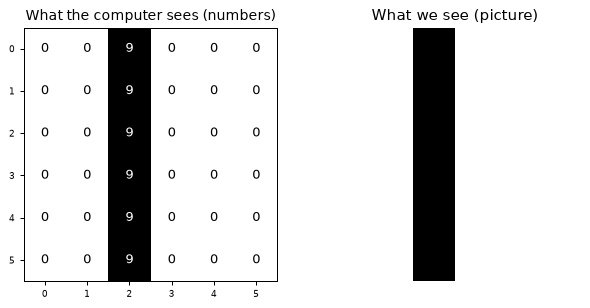

In [3]:
X_line = np.array([
    [0, 0, 9, 0, 0, 0],
    [0, 0, 9, 0, 0, 0],
    [0, 0, 9, 0, 0, 0],
    [0, 0, 9, 0, 0, 0],
    [0, 0, 9, 0, 0, 0],
    [0, 0, 9, 0, 0, 0],
], dtype=float)

print("The image as numbers:\n", X_line)
print("Shape (rows, columns):", X_line.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
show_matrix(axes[0], X_line, "What the computer sees (numbers)")
axes[1].imshow(X_line, cmap="Greys"); axes[1].set_title("What we see (picture)"); axes[1].axis("off")
plt.show()

**✏️ Your turn:** change one `0` in `X_line` to `9` and re-run. What changed in the picture?
**Key idea:** everything a CNN does is arithmetic on these numbers.

---
# Part A — Convolutions for Images  ([D2L §7.2](https://d2l.ai/chapter_convolutional-neural-networks/conv-layer.html))

## A.1 The cross-correlation operation (D2L §7.2.1)

A **kernel** (or **filter**) is a small matrix. We place it on a window of the input of the same size, then:
1. **multiply** each pair of overlapping numbers (element-wise), and
2. **add** all the products → **one** output number.

$$
Y[i, j] = \sum_{a=0}^{k_h-1}\sum_{b=0}^{k_w-1} X[i+a,\; j+b]\cdot K[a, b]
$$

Then the window slides right, then down. An $n_h\times n_w$ input with a $k_h\times k_w$ kernel gives an output of size
$(n_h-k_h+1)\times(n_w-k_w+1)$.

* ### Example 
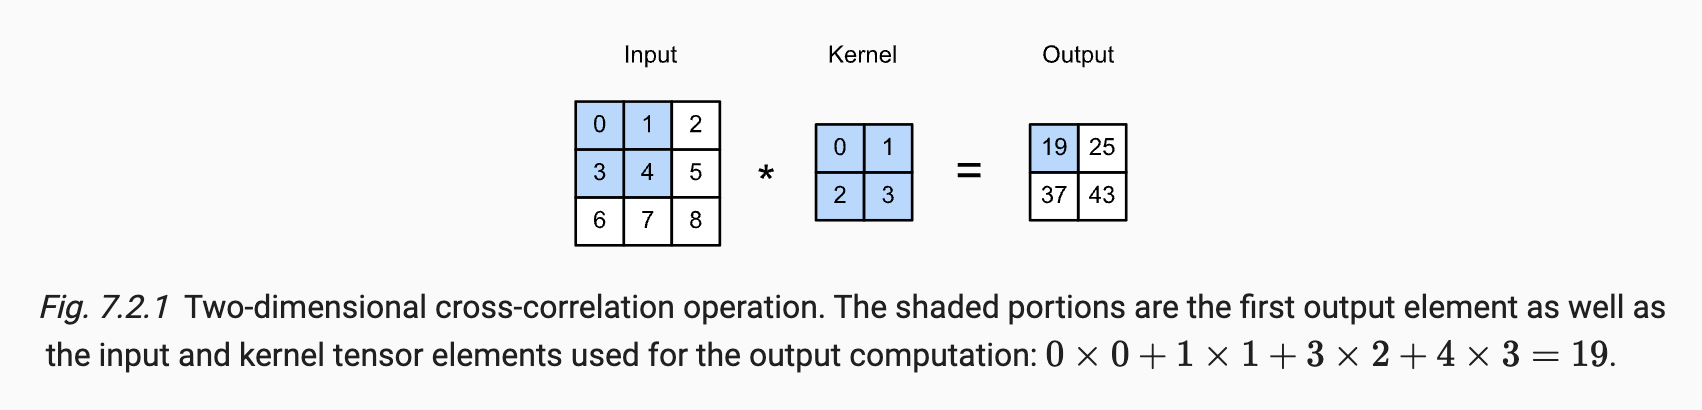

Input `X` = numbers [[0,1,3], [3,4,5],[6,7,8]] (3×3), kernel `K` = `[[0, 1], [2, 3]]` (2×2) → output is 2×2.

**✏️ Your turn (paper and pencil first!):** compute the top-left output: `0·0 + 1·1 + 3·2 + 4·3 = ?`

window:
 [[0. 1.]
 [3. 4.]] 
kernel:
 [[0. 1.]
 [2. 3.]] 
products:
 [[ 0.  1.]
 [ 6. 12.]] 
sum = 19.0


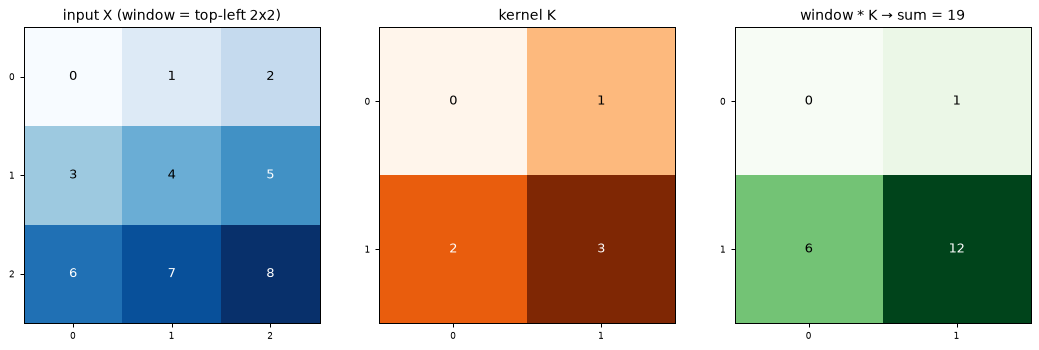

In [4]:
X = np.arange(9, dtype=float).reshape(3, 3)
K = np.array([[0, 1], [2, 3]], dtype=float)

# ONE step: the window at the top-left corner
window = X[0:2, 0:2]
products = window * K
print("window:\n", window, "\nkernel:\n", K, "\nproducts:\n", products, "\nsum =", products.sum())

show_side_by_side([X, K, products], ["input X (window = top-left 2x2)", "kernel K",
                  f"window * K → sum = {products.sum():.0f}"],
                  cmaps=["Blues", "Oranges", "Greens"], figsize=(12, 3.8))

<details><summary>Show answer</summary>

`0·0 + 1·1 + 3·2 + 4·3 = 0 + 1 + 6 + 12 = 19` ✔ (same as the book)
</details>

### A.2 Code it from scratch: `corr2d`
Repeat that one step for **every** position — two `for` loops. This is the same function as `corr2d` in the book,
plus a `verbose` option that **prints every step** and options for padding/stride (used in Part B).

In [5]:
def corr2d(X, K, stride=1, padding=0, verbose=False):

    '''2-D cross-correlation from scratch (D2L §7.2.1), with optional
    padding and stride (§7.3).
    X: input (H x W), K: kernel (kh x kw).
    padding = zero rows/cols added on EACH side; stride = jump size.
    Both can be an int or a (height, width) pair.'''

    X = np.asarray(X, dtype=float)
    K = np.asarray(K, dtype=float)

    ph, pw = (padding, padding) if np.isscalar(padding) else padding
    sh, sw = (stride, stride) if np.isscalar(stride) else stride
    X = np.pad(X, ((ph, ph), (pw, pw)), mode="constant", constant_values=0)
    H, W = X.shape
    kh, kw = K.shape
    out_h = (H - kh) // sh + 1
    out_w = (W - kw) // sw + 1
    Y = np.zeros((out_h, out_w))

    for i in range(out_h):                  # slide down
        for j in range(out_w):              # slide right
            r, c = i * sh, j * sw           # top-left corner of the window
            window = X[r:r + kh, c:c + kw]
            Y[i, j] = np.sum(window * K)    # multiply & add
            if verbose:
                terms = " + ".join(f"{a:g}*{b:g}" for a, b in zip(window.ravel(), K.ravel()))
                print(f"step {i*out_w + j + 1:2d}: Y[{i},{j}] = {terms} = {Y[i, j]:g}")
    return Y

Y = corr2d(X, K, verbose=True)
print("\nOutput Y:\n", Y, "\n(book: [[19, 25], [37, 43]])")

step  1: Y[0,0] = 0*0 + 1*1 + 3*2 + 4*3 = 19
step  2: Y[0,1] = 1*0 + 2*1 + 4*2 + 5*3 = 25
step  3: Y[1,0] = 3*0 + 4*1 + 6*2 + 7*3 = 37
step  4: Y[1,1] = 4*0 + 5*1 + 7*2 + 8*3 = 43

Output Y:
 [[19. 25.]
 [37. 43.]] 
(book: [[19, 25], [37, 43]])


### A.3 Watch it: the kernel sliding, step by step
Use ▶ to play, or the **step buttons** (◀ ▶) to go **one step at a time**.
Watch the **red window** on the input, the **products**, and the **output cell** being filled.

In [6]:
def animate_corr(X, K, stride=1, padding=0, interval=1000, fmt="{:.0f}"):
    Xp = np.pad(np.asarray(X, float), padding)
    kh, kw = K.shape
    full = corr2d(X, K, stride=stride, padding=padding)
    oh, ow = full.shape
    vmax_out = np.abs(full).max() or 1
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.4),
                             gridspec_kw={"width_ratios": [Xp.shape[1], max(kw, 2), max(kw, 2), max(ow, 2)]})

    def draw(frame):
        i, j = divmod(frame, ow)
        r, c = i * stride, j * stride
        for ax in axes: ax.clear()
        title_in = "input" + (f" (padding={padding})" if padding else "") + (f", stride={stride}" if stride > 1 else "")
        show_matrix(axes[0], Xp, title_in, cmap="Blues", highlight=(r, c, kh, kw, "red"), fmt=fmt)
        show_matrix(axes[1], K, "kernel", cmap="coolwarm", fmt=fmt)
        prod = Xp[r:r+kh, c:c+kw] * K
        show_matrix(axes[2], prod, f"products\nsum = {prod.sum():g}", cmap="coolwarm", fmt=fmt)
        partial = np.full_like(full, np.nan)
        partial.ravel()[:frame + 1] = full.ravel()[:frame + 1]
        show_matrix(axes[3], partial, f"output (step {frame+1}/{oh*ow})", cmap="coolwarm",
                    vmin=-vmax_out, vmax=vmax_out, highlight=(i, j, 1, 1, "red"), fmt=fmt)
        fig.tight_layout()

    anim = FuncAnimation(fig, draw, frames=oh * ow, interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml())

animate_corr(X, K)

Now a 3×3 **vertical-edge** kernel on our warm-up image (16 steps). Before playing, guess: where will the output be **positive**, **negative**, **zero**?

In [7]:
K_vertical = np.array([[2, 0, -2],
                       [2, 0, -2],
                       [2, 0, -2]], dtype=float)
animate_corr(X_line, K_vertical, interval=700)

* **+27** where the window has bright on the left and dark on the right, **−27** for the opposite, **0** where the window is uniform.
* The output is a map of *"where are the vertical edges?"* — a **feature map** (more in A.7).

## A.4 Convolutional layers = kernel + bias (D2L §7.2.2)
A convolutional **layer** cross-correlates the input with its kernel and then **adds a scalar bias**.
The kernel and bias are the layer's **learnable parameters** (we will learn them in A.6).

In [8]:
class SimpleConv2D:
    '''A convolutional layer from scratch (D2L §7.2.2).'''
    def __init__(self, kernel_size, seed=0):
        rng = np.random.default_rng(seed)
        self.weight = rng.random(kernel_size)   # random start — training will change it
        self.bias = 0.0

    def __call__(self, X):
        return corr2d(X, self.weight) + self.bias

layer = SimpleConv2D((2, 2))
print("random weight:\n", layer.weight, "\nbias:", layer.bias)
print("output on X:\n", layer(X))

random weight:
 [[0.64 0.27]
 [0.04 0.02]] 
bias: 0.0
output on X:
 [[0.46 1.42]
 [3.35 4.32]]


## A.5 Object edge detection in images (D2L §7.2.3)
The book's example: a 6×8 image of ones (white) with the middle 4 columns set to 0 (black),
and the tiny kernel `K = [[1, -1]]` (difference between neighboring pixels).

Output (book: 1 at white→black edge, -1 at black→white edge):
 [[ 0.  1.  0.  0.  0. -1.  0.]
 [ 0.  1.  0.  0.  0. -1.  0.]
 [ 0.  1.  0.  0.  0. -1.  0.]
 [ 0.  1.  0.  0.  0. -1.  0.]
 [ 0.  1.  0.  0.  0. -1.  0.]
 [ 0.  1.  0.  0.  0. -1.  0.]]

On the TRANSPOSED image:
 [[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


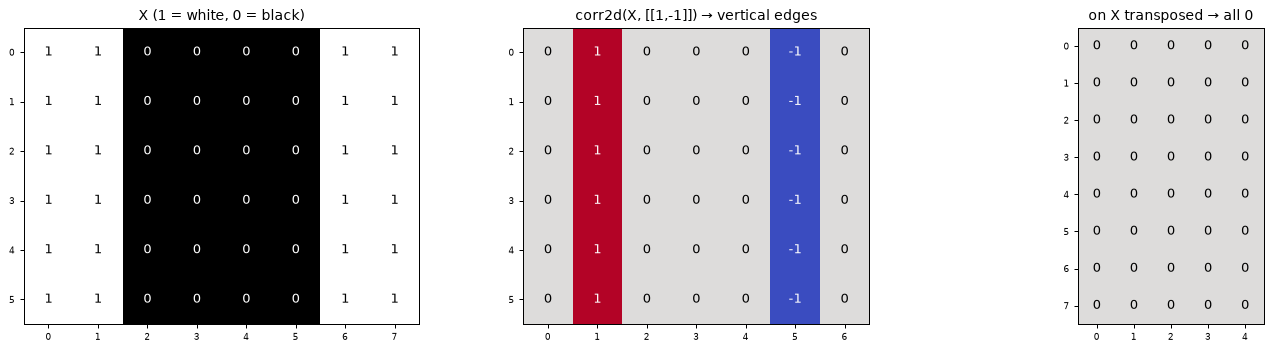

In [9]:
X_edge = np.ones((6, 8))
X_edge[:, 2:6] = 0
K_edge = np.array([[1.0, -1.0]])

Y_edge = corr2d(X_edge, K_edge)
print("Output (book: 1 at white→black edge, -1 at black→white edge):\n", Y_edge)
print("\nOn the TRANSPOSED image:\n", corr2d(X_edge.T, K_edge))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
show_matrix(axes[0], X_edge, "X (1 = white, 0 = black)", cmap="gray")
show_matrix(axes[1], Y_edge, "corr2d(X, [[1,-1]]) → vertical edges", cmap="coolwarm", vmin=-1, vmax=1)
show_matrix(axes[2], corr2d(X_edge.T, K_edge), "on X transposed → all 0", cmap="coolwarm", vmin=-1, vmax=1)
plt.tight_layout(); plt.show()

**✏️ Your turn:** which kernel would detect the **horizontal** edges of `X_edge.T`? Try it.

<details><summary>Show answer</summary>

The transposed kernel `[[1], [-1]]`: `corr2d(X_edge.T, K_edge.T)`.
</details>

### More hand-designed kernels on a small image
Each kernel highlights a different feature.

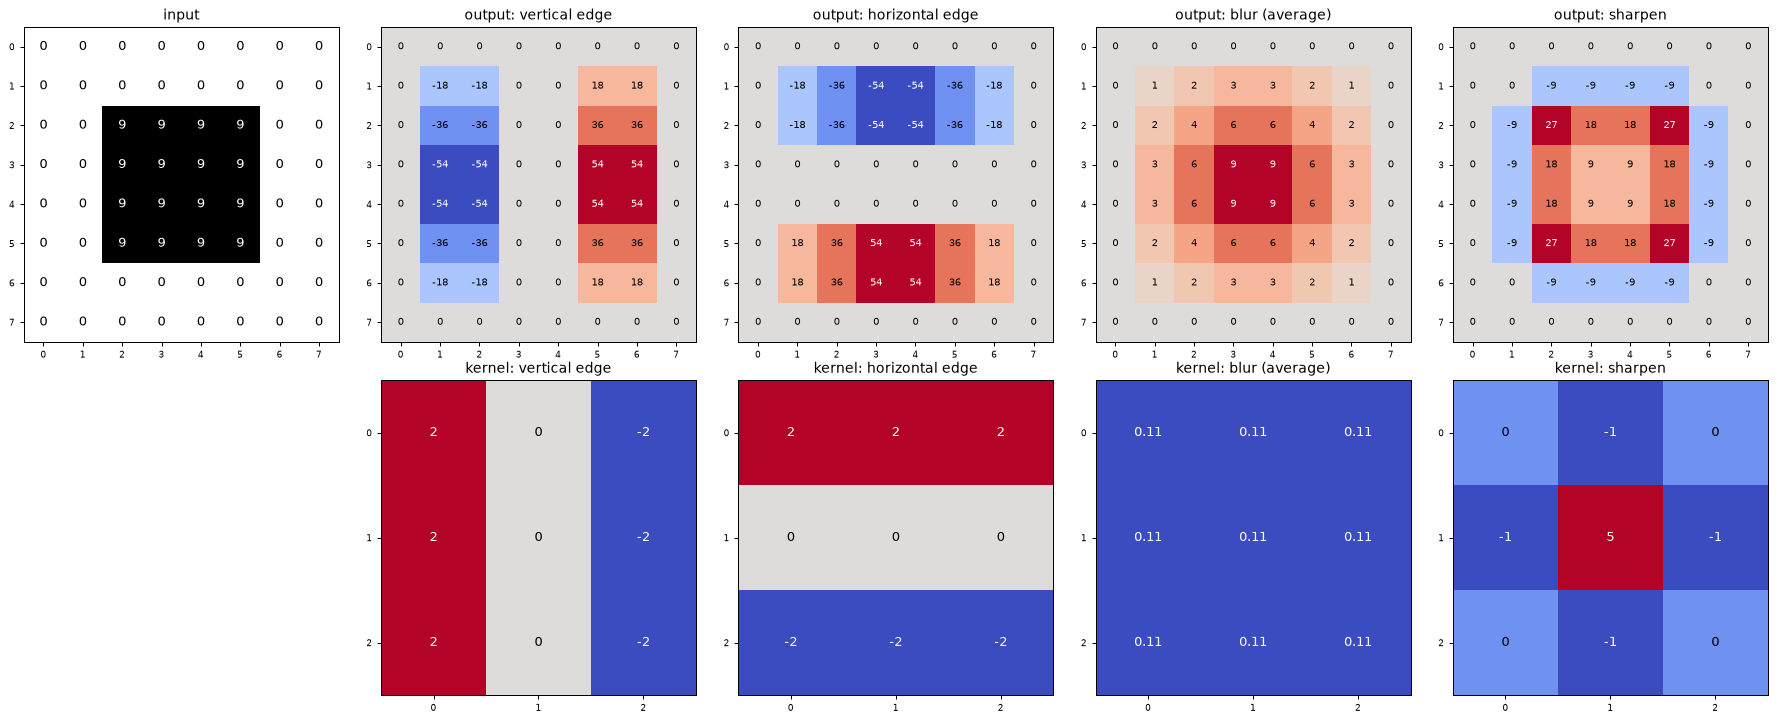

In [10]:
square = np.zeros((8, 8))
square[2:6, 2:6] = 9

kernels = {
    "vertical edge":   K_vertical,
    "horizontal edge": K_vertical.T.copy(),
    "blur (average)":  np.ones((3, 3)) / 9,
    "sharpen":         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
show_matrix(axes[0, 0], square, "input"); axes[1, 0].axis("off")
for col, (name, k) in enumerate(kernels.items(), start=1):
    show_matrix(axes[1, col], k, f"kernel: {name}", cmap="coolwarm", fmt="{:.2g}")
    out = corr2d(square, k, padding=1)
    m = np.abs(out).max()
    show_matrix(axes[0, col], out, f"output: {name}", cmap="coolwarm", vmin=-m, vmax=m, fontsize=8)
plt.tight_layout(); plt.show()

### A.5b The same small kernel on a REAL image (the big matrix)
A photo is the same thing — just a much bigger matrix. Let's load the classic "cameraman" photo.

shape: (256, 256) | min: 10.00019586898593 | max: 249.9958580028534 | number of pixels: 65536


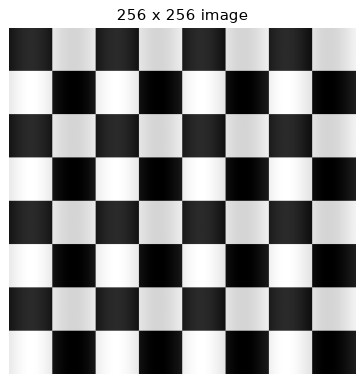

In [11]:
try:
    from skimage import data
    img_full = data.camera().astype(float)          # 512 x 512, values 0..255
except Exception:
    yy, xx = np.mgrid[0:512, 0:512]                 # fallback: synthetic image
    img_full = (((xx // 64 + yy // 64) % 2) * 200 + 30 + 20 * np.sin(xx / 20)).astype(float)

img = img_full[::2, ::2]   # downsample to 256 x 256 so our Python loops stay fast
print("shape:", img.shape, "| min:", img.min(), "| max:", img.max(), "| number of pixels:", img.size)
plt.figure(figsize=(5, 5)); plt.imshow(img, cmap="gray"); plt.title("256 x 256 image"); plt.axis("off"); plt.show()

**Zoom in:** we cut out a 10×10 patch (red box) and print its pixel values. The photo really is numbers.

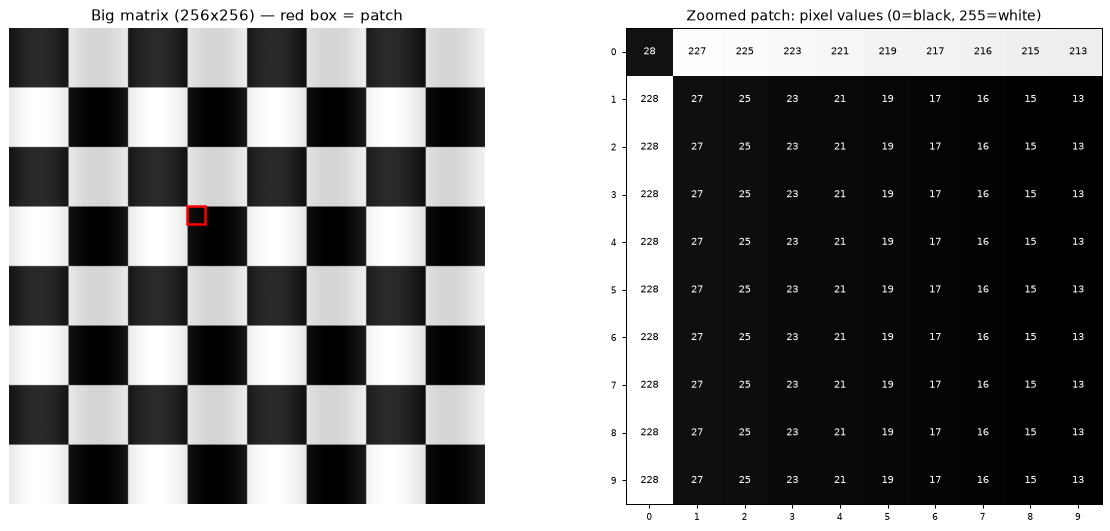

In [12]:
top, left, size = 95, 95, 10      # patch location: an edge of the camera / coat
patch = img[top:top + size, left:left + size]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(img, cmap="gray")
axes[0].add_patch(Rectangle((left, top), size, size, fill=False, ec="red", lw=2))
axes[0].set_title("Big matrix (256x256) — red box = patch"); axes[0].axis("off")
show_matrix(axes[1], patch, "Zoomed patch: pixel values (0=black, 255=white)", cmap="gray", fontsize=8)
plt.tight_layout(); plt.show()

**Small kernel × big matrix — step by step.** The 3×3 kernel slides over the patch exactly as in A.3.
The left panel shows (in yellow) where the kernel is inside the whole photo.

In [13]:
def animate_corr_on_image(img, K, top, left, size=10, interval=350):
    patch = img[top:top+size, left:left+size]
    out = corr2d(patch, K)
    oh, ow = out.shape
    kh, kw = K.shape
    m = np.abs(out).max() or 1
    fig, axes = plt.subplots(1, 4, figsize=(19, 5), gridspec_kw={"width_ratios": [1.1, 1.3, 0.45, 1.1]})

    def draw(frame):
        i, j = divmod(frame, ow)
        for ax in axes: ax.clear()
        axes[0].imshow(img, cmap="gray"); axes[0].axis("off")
        axes[0].add_patch(Rectangle((left, top), size, size, fill=False, ec="red", lw=2))
        axes[0].add_patch(Rectangle((left + j, top + i), kw, kh, fill=True, color="yellow"))
        axes[0].set_title("whole image (yellow = kernel)")
        show_matrix(axes[1], patch, "patch values", cmap="gray", highlight=(i, j, kh, kw, "red"), fontsize=7)
        show_matrix(axes[2], K, "kernel", cmap="coolwarm")
        partial = np.full_like(out, np.nan)
        partial.ravel()[:frame + 1] = out.ravel()[:frame + 1]
        show_matrix(axes[3], partial, f"output = {out[i, j]:.0f}  (step {frame+1}/{oh*ow})",
                    cmap="coolwarm", vmin=-m, vmax=m, highlight=(i, j, 1, 1, "black"), fontsize=7)
        fig.tight_layout()

    anim = FuncAnimation(fig, draw, frames=oh * ow, interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml())

animate_corr_on_image(img, K_vertical, top, left)

**Now the whole big matrix:** same function, same kernel, all 256×256 pixels (~65,000 windows × 9 multiplications).

Loop version took 0.34 s, output shape (256, 256)


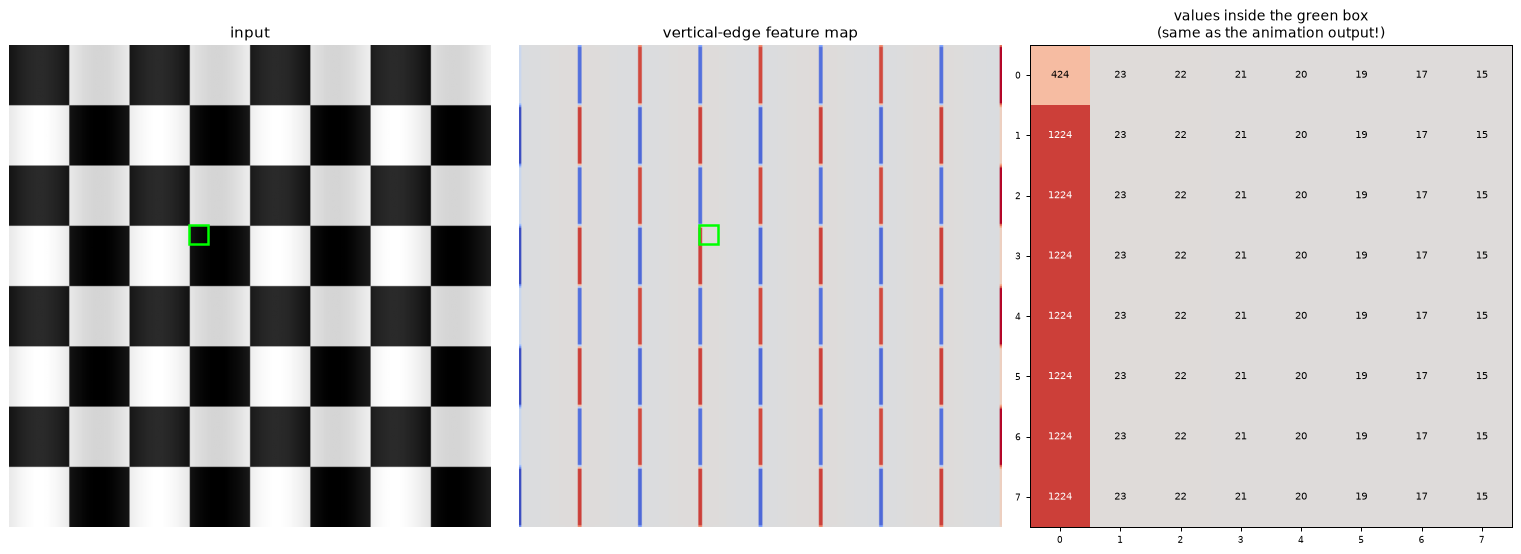

In [14]:
t0 = time.time()
edges_v = corr2d(img, K_vertical, padding=1)
print(f"Loop version took {time.time() - t0:.2f} s, output shape {edges_v.shape}")

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("input"); axes[0].axis("off")
m = np.abs(edges_v).max()
axes[1].imshow(edges_v, cmap="coolwarm", vmin=-m, vmax=m); axes[1].set_title("vertical-edge feature map"); axes[1].axis("off")


for ax in axes[:2]:
    ax.add_patch(Rectangle((left, top), size, size, fill=False, ec="lime", lw=2))
check = edges_v[top + 1: top + size - 1, left + 1: left + size - 1]   # +1 because of padding=1
show_matrix(axes[2], check, "values inside the green box\n(same as the animation output!)", cmap="coolwarm",
            vmin=-m, vmax=m, fontsize=8)
plt.tight_layout(); plt.show()

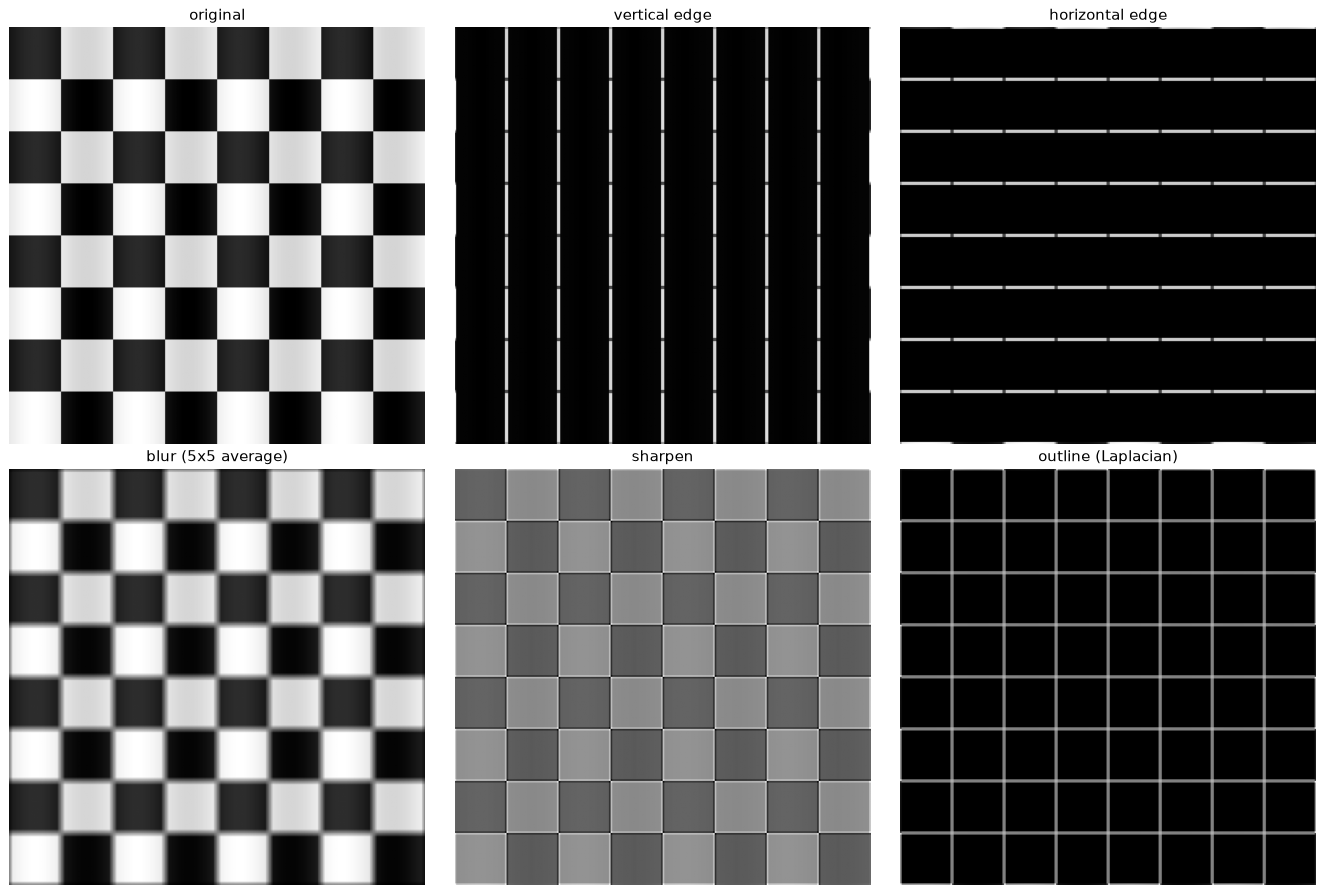

In [15]:
big_kernels = {
    "vertical edge": K_vertical,
    "horizontal edge": K_vertical.T.copy(),
    "blur (5x5 average)": np.ones((5, 5)) / 25,
    "sharpen": kernels["sharpen"],
    "outline (Laplacian)": np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], float),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
axes[0].imshow(img, cmap="gray"); axes[0].set_title("original"); axes[0].axis("off")
for ax, (name, k) in zip(axes[1:], big_kernels.items()):
    out = corr2d(img, k, padding=k.shape[0] // 2)
    if "edge" in name or "outline" in name:
        out = np.abs(out)
    ax.imshow(out, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()

**Speed:** real libraries don't use Python loops. Here is the **same math**, vectorized. Identical result, much faster.

In [16]:
def corr2d_fast(X, K, padding=0):
    X = np.pad(np.asarray(X, float), padding)
    windows = sliding_window_view(X, K.shape)          # (out_h, out_w, kh, kw)
    return np.einsum("ijkl,kl->ij", windows, K)         # multiply & sum for all windows at once

t0 = time.time(); a = corr2d(img, K_vertical, padding=1); t_loop = time.time() - t0
t0 = time.time(); b = corr2d_fast(img, K_vertical, padding=1); t_fast = time.time() - t0
print(f"loops: {t_loop:.3f}s | vectorized: {t_fast:.4f}s | same result: {np.allclose(a, b)}")

loops: 0.287s | vectorized: 0.0025s | same result: True


## A.6 Learning a kernel (D2L §7.2.4)
Hand-designing kernels is fine for edges, but for complex patterns we want the network to **learn** them.
Experiment from the book: we know `Y_edge` was made from `X_edge` with `[[1, -1]]`. Start from a **random** 1×2 kernel
and use gradient descent on the squared error to recover it. Watch the kernel values change each epoch.

**The gradient (no framework needed):** with loss $L = \sum_{i,j} (\hat{Y}_{ij} - Y_{ij})^2$ and $\hat Y = \text{corr2d}(X, K)$,
$$\frac{\partial L}{\partial K[a,b]} = \sum_{i,j} 2(\hat{Y}_{ij}-Y_{ij})\, X[i+a, j+b] = \text{corr2d}\big(X,\; 2(\hat Y - Y)\big)[a,b]$$
The gradient of a convolution is **itself a cross-correlation** — we can reuse our own `corr2d`!

epoch 2, loss 3.730, kernel = [ 0.64 -0.65]
epoch 4, loss 0.626, kernel = [ 0.85 -0.86]
epoch 6, loss 0.105, kernel = [ 0.94 -0.94]
epoch 8, loss 0.018, kernel = [ 0.97 -0.98]
epoch 10, loss 0.003, kernel = [ 0.99 -0.99]


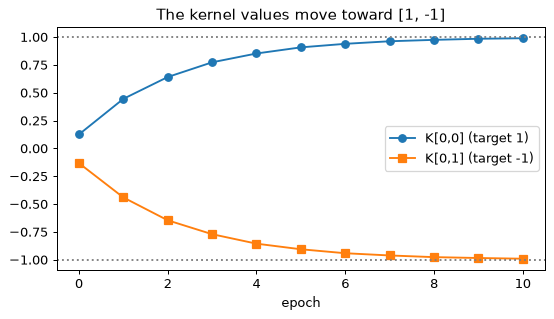

In [17]:
rng = np.random.default_rng(0)
K_learn = rng.normal(0, 1, size=(1, 2))          # random start
lr = 3e-2                                        # learning rate (same as the book)

history_k = [K_learn.ravel().copy()]
for epoch in range(10):
    Y_hat = corr2d(X_edge, K_learn)              # 1. forward
    err = Y_hat - Y_edge
    loss = np.sum(err ** 2)                      # 2. squared error
    grad = corr2d(X_edge, 2 * err)               # 3. gradient dL/dK (shape 1x2)
    K_learn -= lr * grad                         # 4. gradient descent step
    history_k.append(K_learn.ravel().copy())
    if (epoch + 1) % 2 == 0:
        print(f"epoch {epoch + 1}, loss {loss:.3f}, kernel = {K_learn.ravel()}")

history_k = np.array(history_k)
plt.figure(figsize=(7, 3.5))
plt.plot(history_k[:, 0], "o-", label="K[0,0] (target 1)"); plt.plot(history_k[:, 1], "s-", label="K[0,1] (target -1)")
plt.axhline(1, ls=":", c="gray"); plt.axhline(-1, ls=":", c="gray")
plt.xlabel("epoch"); plt.title("The kernel values move toward [1, -1]"); plt.legend(); plt.show()

**This is the heart of a CNN:** the kernels are **parameters learned from data**, not designed by hand.

## A.7 Cross-correlation vs. convolution (D2L §7.2.5)
Strict mathematical *convolution* flips the kernel horizontally and vertically before sliding.
Since CNN kernels are learned, a network would simply learn the flipped kernel — the output is the same.
That's why deep-learning libraries compute cross-correlation but still call it "convolution".

In [18]:
# NumPy has BOTH operations built in for 1-D signals:
x1 = np.array([1., 2., 3., 4., 5.])
k1 = np.array([1., 0., -1.])
print("np.correlate (cross-correlation):   ", np.correlate(x1, k1, mode="valid"))
print("np.convolve  (true convolution):    ", np.convolve(x1, k1, mode="valid"))
print("np.correlate with the FLIPPED kernel:", np.correlate(x1, k1[::-1], mode="valid"))

# In 2-D: true convolution = our corr2d with the kernel flipped up-down AND left-right
K_demo = np.array([[1, 2], [3, 4]], float)
print("\n2-D true convolution of X with K_demo:\n", corr2d(X, np.flip(K_demo)))

np.correlate (cross-correlation):    [-2. -2. -2.]
np.convolve  (true convolution):     [2. 2. 2.]
np.correlate with the FLIPPED kernel: [2. 2. 2.]

2-D true convolution of X with K_demo:
 [[13. 23.]
 [43. 53.]]


## A.8 Feature map and receptive field (D2L §7.2.6)
* **Feature map:** the output of a conv layer — a learned representation of the input in space.
* **Receptive field** of an output element: all input elements that can affect it.
  With 2×2 kernels: one element of the 1st output sees **4** input cells; stack another 2×2 layer and one element sees a **3×3** region.
  **Deeper layers see bigger regions** of the image.

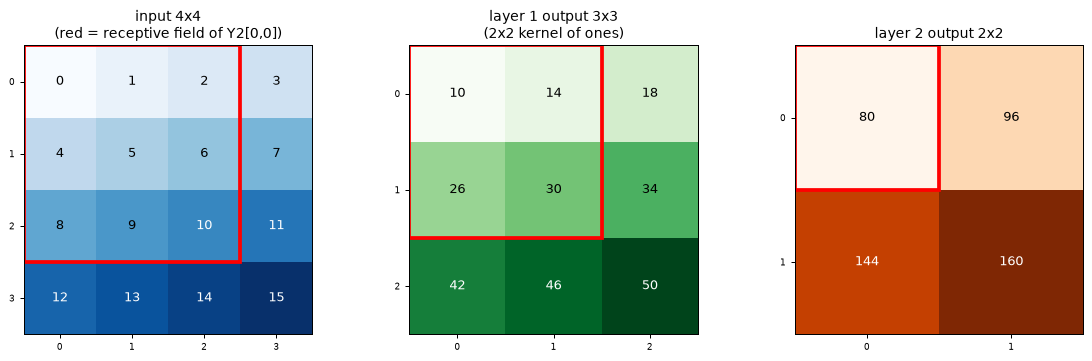

In [19]:
X_rf = np.arange(16, dtype=float).reshape(4, 4)
Y1 = corr2d(X_rf, np.ones((2, 2)))        # 3x3
Y2 = corr2d(Y1, np.ones((2, 2)))          # 2x2
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
show_matrix(axes[0], X_rf, "input 4x4\n(red = receptive field of Y2[0,0])", cmap="Blues", highlight=(0, 0, 3, 3, "red"))
show_matrix(axes[1], Y1, "layer 1 output 3x3\n(2x2 kernel of ones)", cmap="Greens", highlight=(0, 0, 2, 2, "red"))
show_matrix(axes[2], Y2, "layer 2 output 2x2", cmap="Oranges", highlight=(0, 0, 1, 1, "red"))
plt.tight_layout(); plt.show()

---
# Part B — Padding and Stride  ([D2L §7.3](https://d2l.ai/chapter_convolutional-neural-networks/padding-and-strides.html))

* **Padding:** add zeros around the border so the output does not shrink and border pixels are used fully.
* **Stride:** how many cells the window jumps each step. Stride 2 roughly halves the output size.

**General formula from the book** (with $p_h$ = **total** rows of padding, top + bottom):
$$
\left\lfloor \frac{n_h - k_h + p_h + s_h}{s_h} \right\rfloor \times \left\lfloor \frac{n_w - k_w + p_w + s_w}{s_w} \right\rfloor
$$
Common choice: $p_h = k_h - 1$ (e.g. 3×3 kernel → 1 row of zeros on each side) keeps the size the same when stride = 1.

> ⚠️ In our `corr2d(..., padding=p)` (and in most libraries), `p` is the padding on **each** side, so the book's total $p_h = 2p$.

In [20]:
def out_size(n, k, p_total=0, s=1):
    '''D2L formula: p_total = total padding (both sides).'''
    return (n - k + p_total + s) // s

for p, s in [(0, 1), (1, 1), (0, 2), (1, 2)]:
    Y = corr2d(X_line, K_vertical, stride=s, padding=p)
    print(f"6x6 input, 3x3 kernel, padding={p} each side, stride={s}: "
          f"formula -> {out_size(6, 3, 2*p, s)}x{out_size(6, 3, 2*p, s)}, actual -> {Y.shape}")

6x6 input, 3x3 kernel, padding=0 each side, stride=1: formula -> 4x4, actual -> (4, 4)
6x6 input, 3x3 kernel, padding=1 each side, stride=1: formula -> 6x6, actual -> (6, 6)
6x6 input, 3x3 kernel, padding=0 each side, stride=2: formula -> 2x2, actual -> (2, 2)
6x6 input, 3x3 kernel, padding=1 each side, stride=2: formula -> 3x3, actual -> (3, 3)


Watch **padding = 1** (the border of zeros) and **stride = 2** (bigger jumps):

In [21]:
animate_corr(X_line, K_vertical, stride=2, padding=1, interval=1200)

### The book's examples (8×8 input), checked with our own `corr2d`
**✏️ Your turn:** use the formula to predict each output shape **before** running.

In [22]:
Xb = np.random.default_rng(0).random((8, 8))
examples = [
    ("3x3 kernel, padding 1",                     (3, 3), 1,      1),
    ("5x3 kernel, padding (2,1)",                 (5, 3), (2, 1), 1),
    ("3x3 kernel, padding 1, stride 2",           (3, 3), 1,      2),
    ("(3,5) kernel, padding (0,1), stride (3,4)", (3, 5), (0, 1), (3, 4)),
]
for name, ksize, pad, stride in examples:
    Y = corr2d(Xb, np.ones(ksize), stride=stride, padding=pad)
    print(f"{name:45s} -> output shape {Y.shape}")

3x3 kernel, padding 1                         -> output shape (8, 8)
5x3 kernel, padding (2,1)                     -> output shape (8, 8)
3x3 kernel, padding 1, stride 2               -> output shape (4, 4)
(3,5) kernel, padding (0,1), stride (3,4)     -> output shape (2, 2)


<details><summary>Show answer</summary>

* 3×3, pad 1: (8−3+2+1)/1 = **8×8**
* 5×3, pad (2,1): height (8−5+4+1) = 8, width (8−3+2+1) = 8 → **8×8**
* 3×3, pad 1, stride 2: ⌊(8−3+2+2)/2⌋ = **4×4**
* (3,5), pad (0,1), stride (3,4): height ⌊(8−3+0+3)/3⌋ = 2, width ⌊(8−5+2+4)/4⌋ = 2 → **2×2**
</details>

---
# Part C — Multiple Input and Multiple Output Channels  ([D2L §7.4](https://d2l.ai/chapter_convolutional-neural-networks/channels.html))

## C.1 Multiple input channels (D2L §7.4.1)
A color image has 3 channels (R, G, B): shape `3 × H × W`. The kernel must have the **same number of channels**.
We cross-correlate **each channel with its own kernel slice**, then **add** the results → still **one** 2-D output.

$$Y[i,j] = \sum_{c} \; \sum_{a,b} X_c[i+a, j+b]\cdot K_c[a,b]$$

### Example: 2 input channels

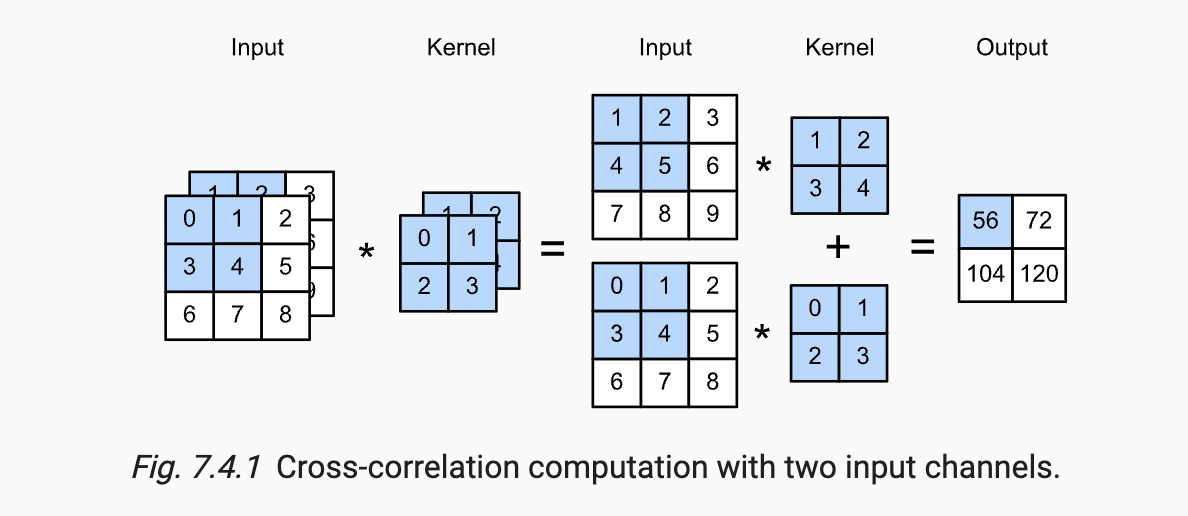


**✏️ Your turn:** compute the top-left output by hand: channel 0 gives `0·0+1·1+3·2+4·3`, channel 1 gives `1·1+2·2+4·3+5·4`. Total = ?

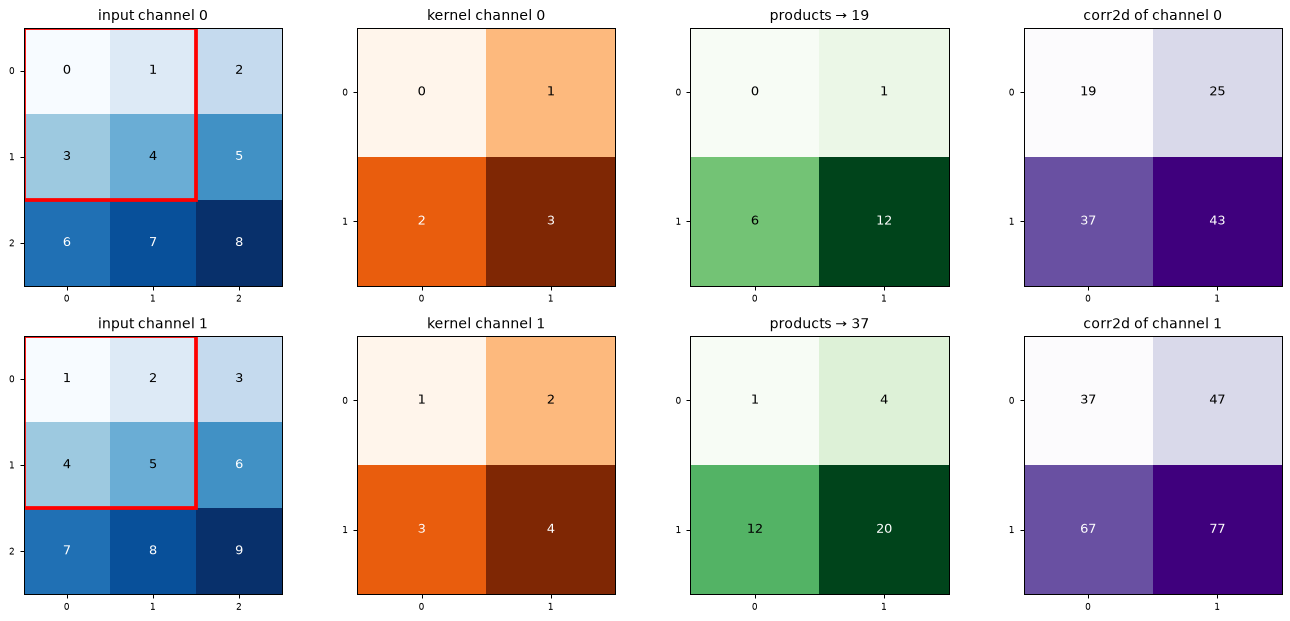

channel 0 + channel 1 =
 [[19. 25.]
 [37. 43.]] 
+
 [[37. 47.]
 [67. 77.]] 
=
 [[ 56.  72.]
 [104. 120.]] 
(book: [[56, 72], [104, 120]])


In [23]:
def corr2d_multi_in(X, K):
    '''Sum of per-channel cross-correlations (D2L §7.4.1). X: (c_i, h, w), K: (c_i, kh, kw)'''
    return sum(corr2d(x, k) for x, k in zip(X, K))

X2 = np.array([[[0, 1, 2], [3, 4, 5], [6, 7, 8]],
               [[1, 2, 3], [4, 5, 6], [7, 8, 9]]], dtype=float)
K2 = np.array([[[0, 1], [2, 3]],
               [[1, 2], [3, 4]]], dtype=float)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
partials = []
for c in range(2):
    p = corr2d(X2[c], K2[c]); partials.append(p)
    show_matrix(axes[c, 0], X2[c], f"input channel {c}", cmap="Blues", highlight=(0, 0, 2, 2, "red"))
    show_matrix(axes[c, 1], K2[c], f"kernel channel {c}", cmap="Oranges")
    show_matrix(axes[c, 2], X2[c, :2, :2] * K2[c], f"products → {np.sum(X2[c, :2, :2] * K2[c]):g}", cmap="Greens")
    show_matrix(axes[c, 3], p, f"corr2d of channel {c}", cmap="Purples")
plt.tight_layout(); plt.show()
print("channel 0 + channel 1 =\n", partials[0], "\n+\n", partials[1], "\n=\n", corr2d_multi_in(X2, K2),
      "\n(book: [[56, 72], [104, 120]])")

<details><summary>Show answer</summary>

channel 0: 0+1+6+12 = 19, channel 1: 1+4+12+20 = 37 → **56** ✔
</details>

## C.2 Multiple output channels (D2L §7.4.2)
Each output channel has **its own** 3-D kernel. With $c_o$ output channels the kernel has shape $c_o \times c_i \times k_h \times k_w$.
Each output channel can learn to detect a **different** pattern. The book stacks `K`, `K+1`, `K+2`:

kernel shape (c_o, c_i, kh, kw): (3, 2, 2, 2)
output shape: (3, 2, 2)


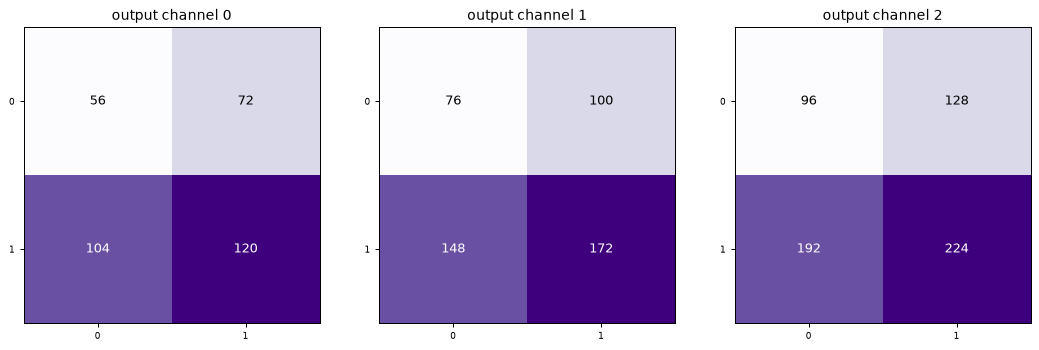

In [24]:
def corr2d_multi_in_out(X, K):
    '''One 3-D kernel per output channel (D2L §7.4.2). K: (c_o, c_i, kh, kw) -> (c_o, h', w')'''
    return np.stack([corr2d_multi_in(X, k) for k in K])

K3 = np.stack([K2, K2 + 1, K2 + 2])
print("kernel shape (c_o, c_i, kh, kw):", K3.shape)
Y3 = corr2d_multi_in_out(X2, K3)
print("output shape:", Y3.shape)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for o in range(3):
    show_matrix(axes[o], Y3[o], f"output channel {o}", cmap="Purples")
plt.tight_layout(); plt.show()

## C.3 The 1×1 convolution (D2L §7.4.3)
A 1×1 kernel looks at **one pixel position** at a time, so it can't detect spatial patterns. It only **mixes channels**:
at every pixel it acts like a small fully-connected layer from $c_i$ to $c_o$ channels. It needs only $c_o \times c_i$ weights (+ bias).
Used a lot in modern CNNs to change the number of channels cheaply.

In [25]:
def corr2d_multi_in_out_1x1(X, K):
    c_i, h, w = X.shape
    c_o = K.shape[0]
    X = X.reshape((c_i, h * w))           # each column = one pixel's channel vector
    K = K.reshape((c_o, c_i))
    Y = K @ X                             # matrix multiplication = a dense layer at every pixel
    return Y.reshape((c_o, h, w))

rng = np.random.default_rng(0)
X_r = rng.normal(0, 1, (3, 3, 3))
K_r = rng.normal(0, 1, (2, 3, 1, 1))
Y_a = corr2d_multi_in_out_1x1(X_r, K_r)
Y_b = corr2d_multi_in_out(X_r, K_r)
print("1x1 conv as matrix multiplication == general version:", np.abs(Y_a - Y_b).sum() < 1e-6)

1x1 conv as matrix multiplication == general version: True


## C.4 A real color image with several filters
Each filter is `3 × 3 × 3` (one 3×3 slice per color channel). 4 filters → 4 feature maps.

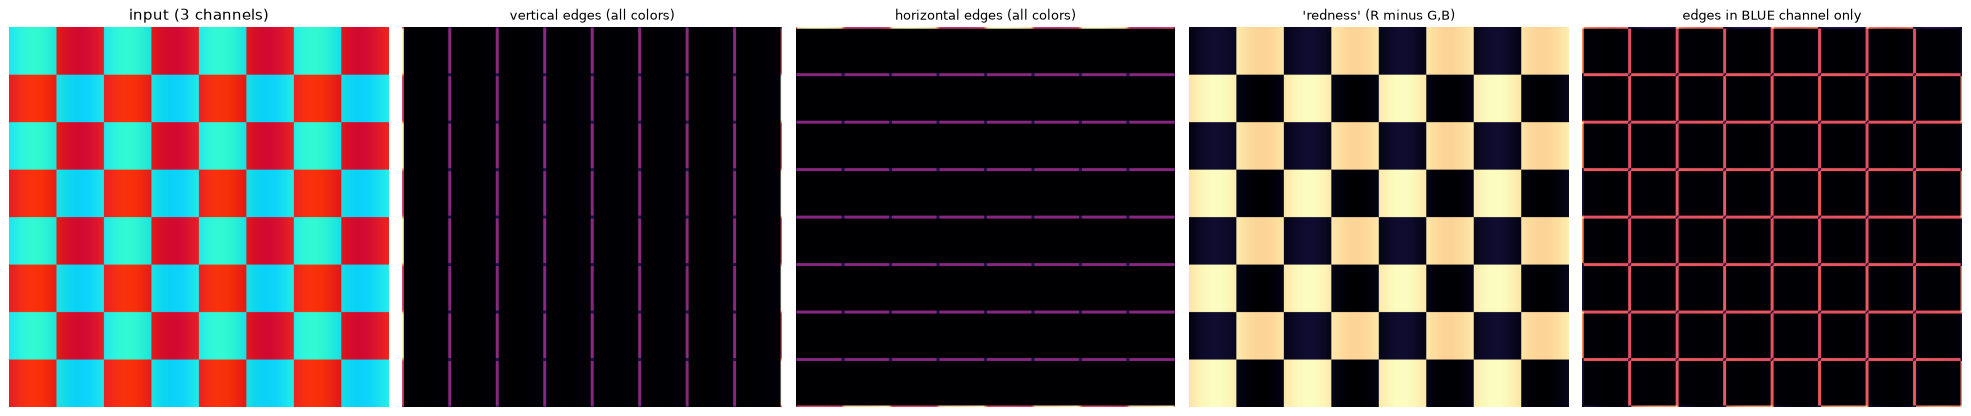

input: (3, 256, 256)  kernel: (4, 3, 3, 3)  -> output: (4, 256, 256)


In [26]:
try:
    rgb = data.astronaut()[::2, ::2].astype(float) / 255     # 256 x 256 x 3
except Exception:
    rgb = np.stack([img / 255, np.flipud(img) / 255, np.fliplr(img) / 255], axis=-1)
X_img = rgb.transpose(2, 0, 1)                                 # -> (3, H, W): channels first

v, h = K_vertical, K_vertical.T
zero = np.zeros((3, 3)); center = np.zeros((3, 3)); center[1, 1] = 1
filters = {
    "vertical edges (all colors)":   np.stack([v, v, v]),
    "horizontal edges (all colors)": np.stack([h, h, h]),
    "'redness' (R minus G,B)":       np.stack([center, -0.5 * center, -0.5 * center]),
    "edges in BLUE channel only":    np.stack([zero, zero, v + h]),
}
K_bank = np.stack(list(filters.values()))                     # (c_o=4, c_i=3, 3, 3)
X_img_pad = np.pad(X_img, ((0, 0), (1, 1), (1, 1)))
fmaps = corr2d_multi_in_out(X_img_pad, K_bank)

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
axes[0].imshow(rgb); axes[0].set_title("input (3 channels)"); axes[0].axis("off")
for ax, name, fm in zip(axes[1:], filters, fmaps):
    ax.imshow(np.abs(fm) if "edge" in name else fm, cmap="magma"); ax.set_title(name, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
print("input:", X_img.shape, " kernel:", K_bank.shape, " -> output:", fmaps.shape)

**✏️ Your turn:** how many learnable parameters does a conv layer have with $c_i=3$, $c_o=16$, a 3×3 kernel, and one bias per output channel?

<details><summary>Show answer</summary>

16 × 3 × 3 × 3 + 16 = **448** — and it does **not** depend on the image size (weight sharing).
</details>

---
# Part D — Pooling  ([D2L §7.5](https://d2l.ai/chapter_convolutional-neural-networks/pooling.html))

A pooling layer slides a window (like convolution) but has **no kernel / no parameters**. It outputs either
the **maximum** (max pooling) or the **average** (average pooling) of the window. Why?
* It **reduces resolution** so deeper layers summarize larger regions.
* It makes the output **less sensitive to small shifts** of the object.


Example 

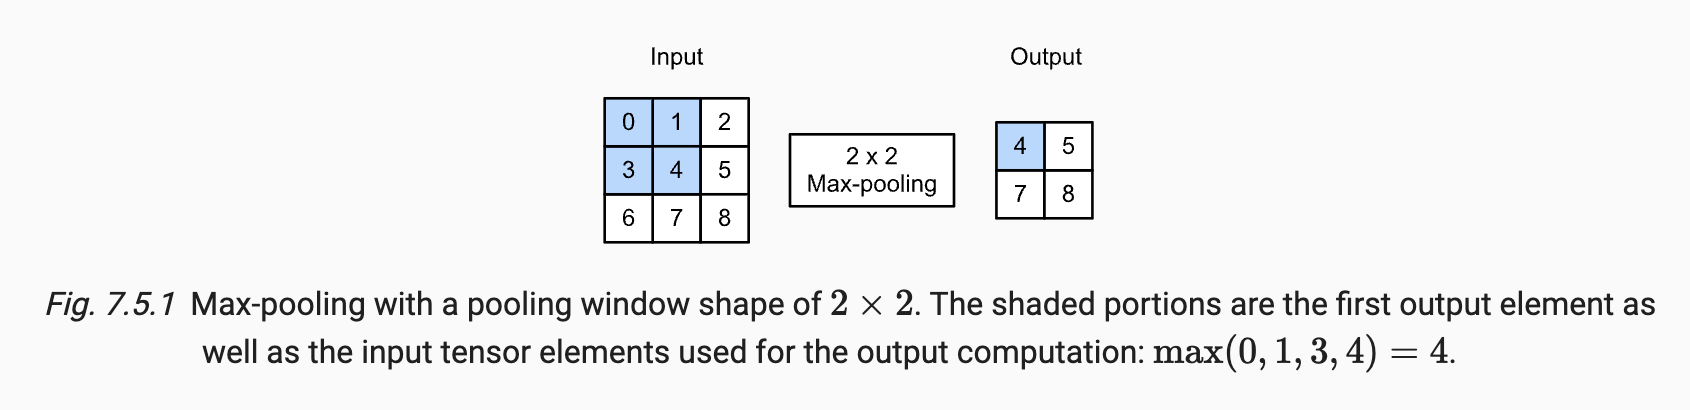

## D.1 Max and average pooling from scratch (D2L §7.5.1)

max pooling (book: [[4, 5], [7, 8]])
window (0,0) = [0. 1. 3. 4.] -> max = 4
window (0,1) = [1. 2. 4. 5.] -> max = 5
window (1,0) = [3. 4. 6. 7.] -> max = 7
window (1,1) = [4. 5. 7. 8.] -> max = 8

average pooling (book: [[2, 3], [5, 6]])
window (0,0) = [0. 1. 3. 4.] -> avg = 2
window (0,1) = [1. 2. 4. 5.] -> avg = 3
window (1,0) = [3. 4. 6. 7.] -> avg = 5
window (1,1) = [4. 5. 7. 8.] -> avg = 6


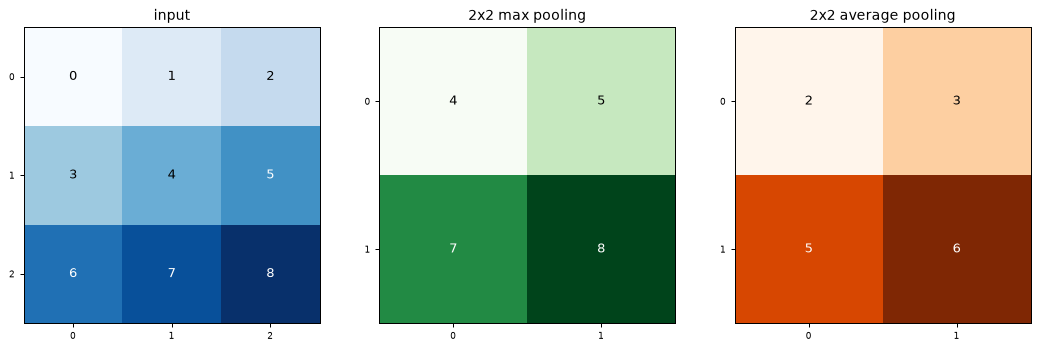

In [27]:
def pool2d(X, pool_size, mode="max", stride=None, padding=0, verbose=False):
    '''Pooling from scratch (D2L §7.5.1). stride defaults to 1 (like the book's pool2d).
    For max pooling the padding is -infinity, so padded cells never win.'''
    X = np.asarray(X, float)
    if padding:
        X = np.pad(X, padding, constant_values=(-np.inf if mode == "max" else 0))
    p_h, p_w = pool_size
    s = stride or 1
    out_h, out_w = (X.shape[0] - p_h) // s + 1, (X.shape[1] - p_w) // s + 1
    Y = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            win = X[i*s:i*s + p_h, j*s:j*s + p_w]
            Y[i, j] = win.max() if mode == "max" else win.mean()
            if verbose:
                print(f"window ({i},{j}) = {win.ravel()} -> {mode} = {Y[i, j]:g}")
    return Y

Xp = np.arange(9, dtype=float).reshape(3, 3)
print("max pooling (book: [[4, 5], [7, 8]])")
Ymax = pool2d(Xp, (2, 2), "max", verbose=True)
print("\naverage pooling (book: [[2, 3], [5, 6]])")
Yavg = pool2d(Xp, (2, 2), "avg", verbose=True)
show_side_by_side([Xp, Ymax, Yavg], ["input", "2x2 max pooling", "2x2 average pooling"],
                  cmaps=["Blues", "Greens", "Oranges"], figsize=(12, 3.8))

### Step by step: activation → 2×2 max pooling with stride 2
In a CNN, pooling usually comes right after an **activation function**. LeNet (Part E) uses **sigmoid**; modern CNNs use **ReLU** $= \max(0, x)$.
Here: ReLU, then 2×2 max pooling with stride 2 (non-overlapping windows) — the size is **halved**.

window (0,0) = [3. 0. 0. 6.] -> max = 6
window (0,1) = [0. 2. 1. 0.] -> max = 2
window (1,0) = [0. 0. 2. 1.] -> max = 2
window (1,1) = [0. 8. 7. 0.] -> max = 8


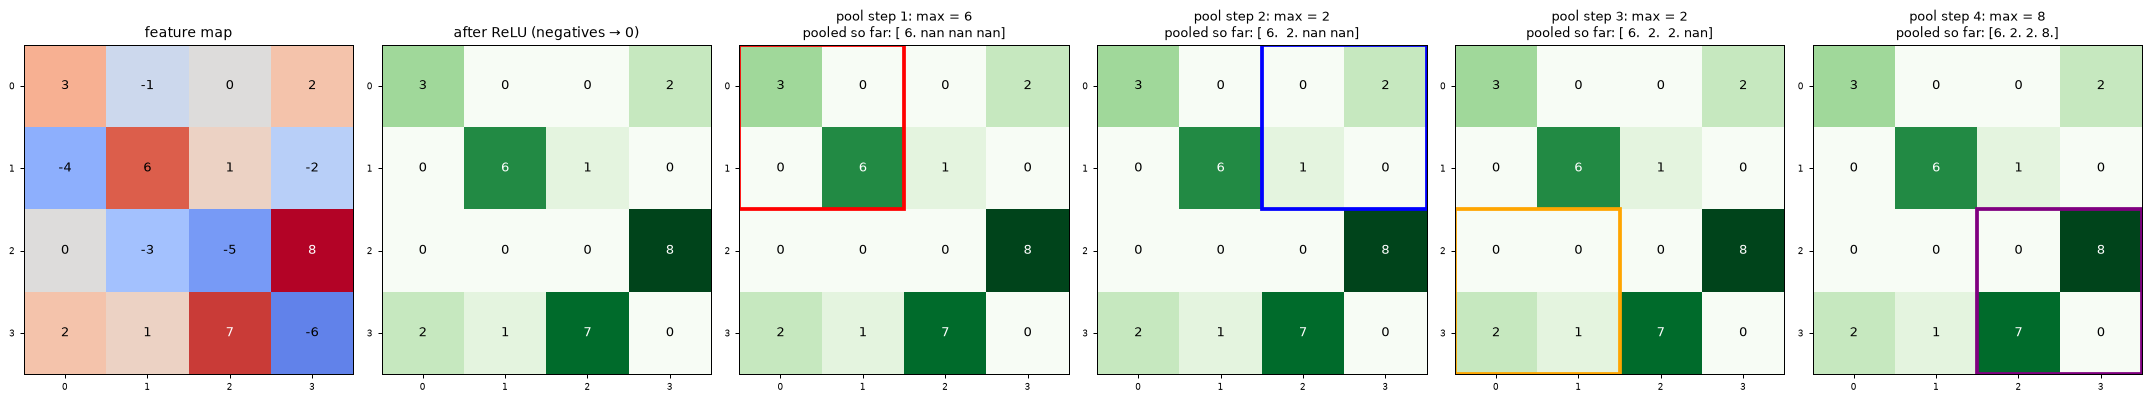

pooled output:
 [[6. 2.]
 [2. 8.]]


In [28]:
def relu(x):
    return np.maximum(0, x)

F = np.array([[ 3, -1,  0,  2],
              [-4,  6,  1, -2],
              [ 0, -3, -5,  8],
              [ 2,  1,  7, -6]], dtype=float)
F_relu = relu(F)
P = pool2d(F_relu, (2, 2), "max", stride=2, verbose=True)

fig, axes = plt.subplots(1, 6, figsize=(24, 4.2))
show_matrix(axes[0], F, "feature map", cmap="coolwarm", vmin=-8, vmax=8)
show_matrix(axes[1], F_relu, "after ReLU (negatives → 0)", cmap="Greens")
colors = ["red", "blue", "orange", "purple"]
for k, (i, j) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1)]):
    partial = np.full((2, 2), np.nan); partial.ravel()[:k + 1] = P.ravel()[:k + 1]
    show_matrix(axes[2 + k], F_relu, "", cmap="Greens", highlight=(2*i, 2*j, 2, 2, colors[k]))
    axes[2 + k].set_title(f"pool step {k+1}: max = {P[i, j]:g}\npooled so far: {partial.ravel()}", fontsize=10)
plt.tight_layout(); plt.show()
print("pooled output:\n", P)

## D.2 Padding and stride in pooling (D2L §7.5.2)
In deep-learning frameworks the **stride defaults to the window size**. The book's example on a 4×4 input:

In [29]:
X4 = np.arange(16, dtype=float).reshape(4, 4)
print("input:\n", X4)
# Frameworks use stride = window size by default; we pass it explicitly.
print("3x3 max pool, stride 3            ->\n", pool2d(X4, (3, 3), "max", stride=3), "  (book: [[10]])")
print("3x3 max pool, padding 1, stride 2 ->\n", pool2d(X4, (3, 3), "max", stride=2, padding=1), "  (book: [[5, 7], [13, 15]])")

input:
 [[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]
 [12. 13. 14. 15.]]
3x3 max pool, stride 3            ->
 [[10.]]   (book: [[10]])
3x3 max pool, padding 1, stride 2 ->
 [[ 5.  7.]
 [13. 15.]]   (book: [[5, 7], [13, 15]])


## D.3 Multiple channels (D2L §7.5.3)
Pooling works on **each channel separately**: the number of output channels = the number of input channels.

In [30]:
X4c = np.stack([X4, X4 + 1])                    # 2 channels: shape (2, 4, 4)
Y4c = np.stack([pool2d(ch, (3, 3), "max", stride=2, padding=1) for ch in X4c])   # pool EACH channel
print("input shape:", X4c.shape, "-> output shape:", Y4c.shape)
print(Y4c)

input shape: (2, 4, 4) -> output shape: (2, 2, 2)
[[[ 5.  7.]
  [13. 15.]]

 [[ 6.  8.]
  [14. 16.]]]


### Pooling on the big image: conv → ReLU → pool → pool. The image gets smaller, but the edges remain.

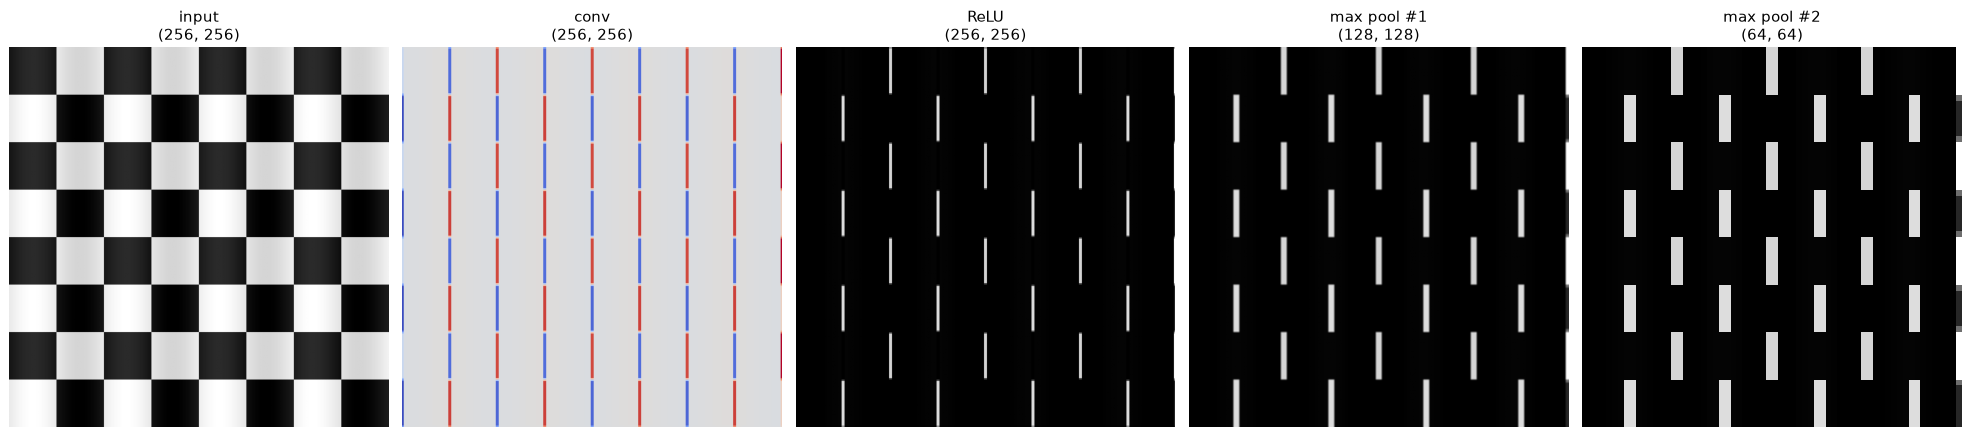

In [31]:
fm = corr2d_fast(img, K_vertical, padding=1)
fm_relu = relu(fm)
fm_pool = pool2d(fm_relu, (2, 2), "max", stride=2)
fm_pool2 = pool2d(fm_pool, (2, 2), "max", stride=2)

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, M, t in zip(axes, [img, fm, fm_relu, fm_pool, fm_pool2],
                    ["input", "conv", "ReLU", "max pool #1", "max pool #2"]):
    ax.imshow(M, cmap="coolwarm" if t == "conv" else "gray"); ax.set_title(f"{t}\n{M.shape}"); ax.axis("off")
plt.tight_layout(); plt.show()

**Shift invariance demo:** move the line one pixel to the right. The convolution output moves, but after max pooling it is (almost) the same.

In [32]:
X_shift = np.roll(X_line, 1, axis=1)
for name, Xs in [("original", X_line), ("shifted 1 px", X_shift)]:
    c = relu(corr2d(Xs, K_vertical, padding=1))
    print(f"{name:13s} conv+ReLU row 0: {c[0]}   ->  max-pooled row 0: {pool2d(c, (2, 2), 'max', stride=2)[0]}")

original      conv+ReLU row 0: [ 0.  0.  0. 36.  0.  0.]   ->  max-pooled row 0: [ 0. 54.  0.]
shifted 1 px  conv+ReLU row 0: [ 0.  0.  0.  0. 36.  0.]   ->  max-pooled row 0: [ 0.  0. 54.]


---
# Part E — Convolutional Neural Networks: LeNet  ([D2L §7.6](https://d2l.ai/chapter_convolutional-neural-networks/lenet.html))

## E.1 Putting the pieces together by hand
Before building the full network, let's connect our **own** functions into a mini CNN on one small 8×8 handwritten digit:


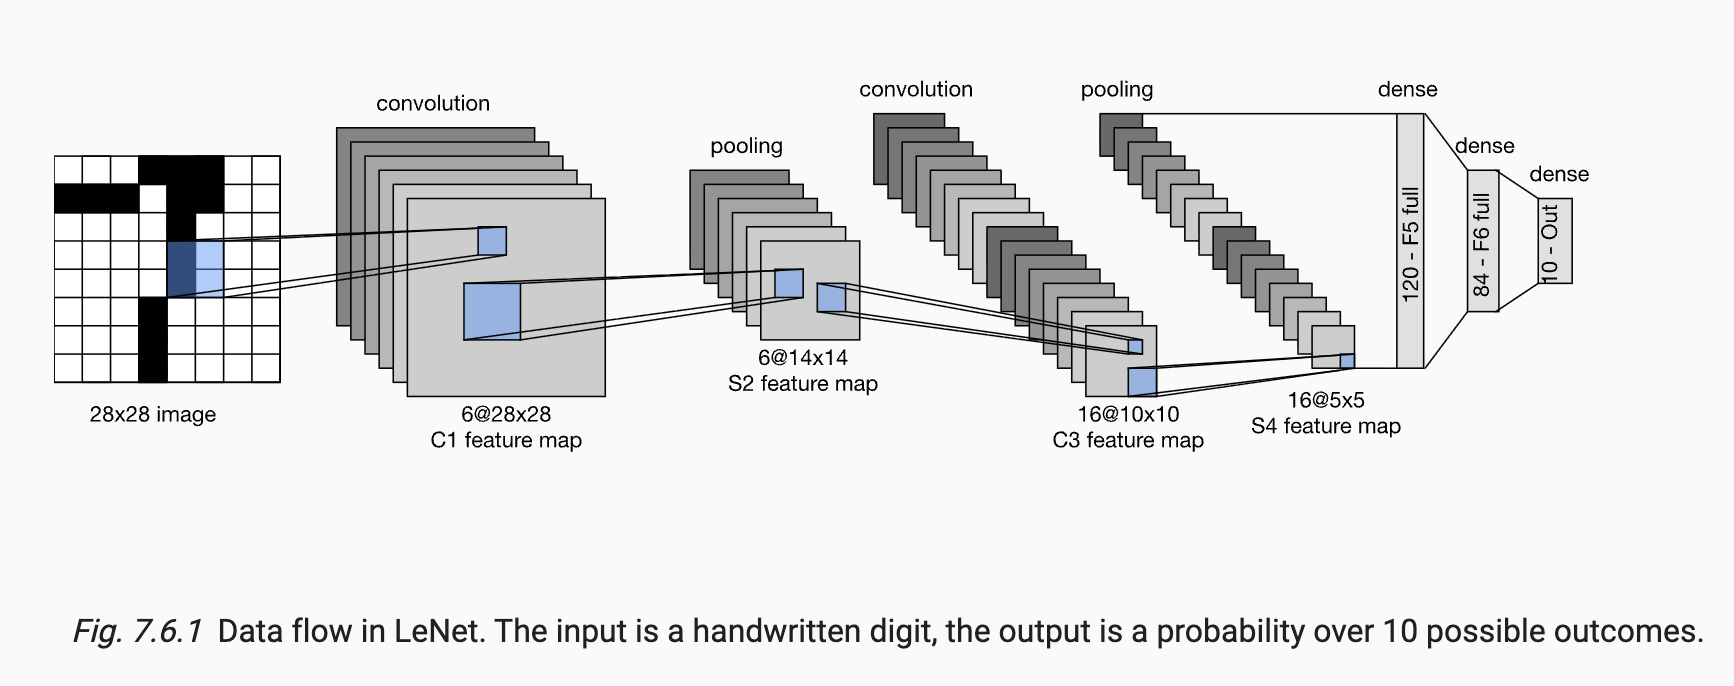

```
image ─▶ conv ─▶ activation ─▶ pool ─▶ flatten ─▶ dense ─▶ softmax ─▶ 10 class probabilities
       └──── convolutional block (features) ───┘   └──── dense block (classifier) ────┘
```
The 4 filters are hand-designed and the dense weights are **random** (not trained) — so the prediction is just a guess. Watch the **shapes**.

input           shape = (8, 8)
conv            shape = (4, 8, 8)
ReLU            shape = (4, 8, 8)
pool            shape = (4, 4, 4)
flatten         shape = (64,)
dense (logits)  shape = (10,)
softmax         shape = (10,)

predicted: 5 | true: 0  (random weights → just a guess!)


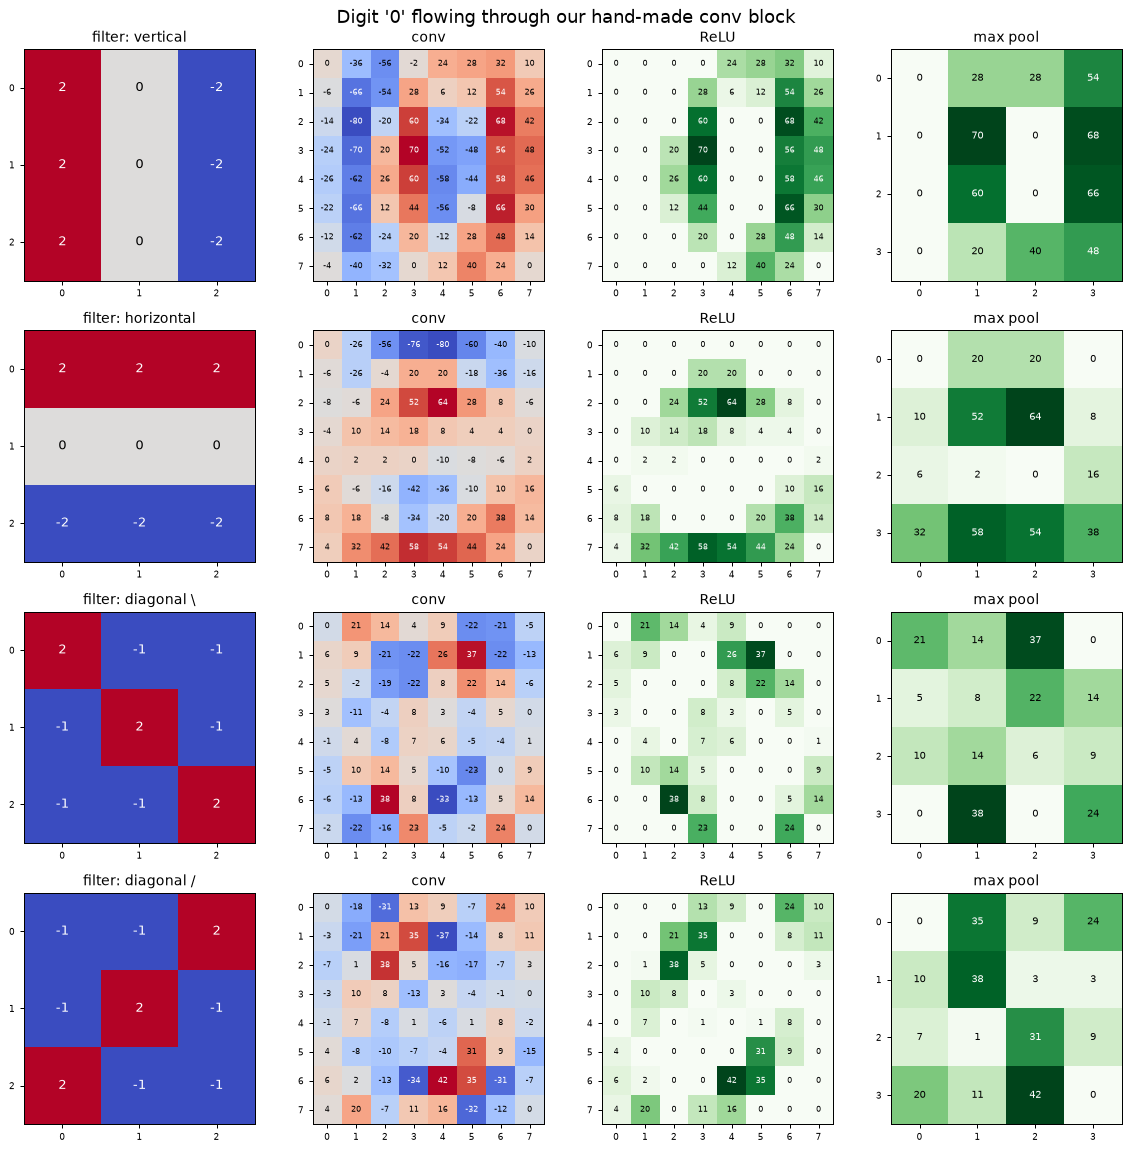

In [33]:
from sklearn.datasets import load_digits
digits = load_digits()
x = digits.images[0]           # an 8x8 image of the digit 0 (values 0..16)

d1 = np.array([[2, -1, -1], [-1, 2, -1], [-1, -1, 2]], float)
cnn_filters = np.stack([K_vertical, K_vertical.T, d1, np.fliplr(d1)])
names = ["vertical", "horizontal", "diagonal \\", "diagonal /"]

conv_out = np.stack([corr2d(x, k, padding=1) for k in cnn_filters])          # (4, 8, 8)
act_out = relu(conv_out)                                                       # (4, 8, 8)
pool_out = np.stack([pool2d(f, (2, 2), "max", stride=2) for f in act_out])     # (4, 4, 4)
flat = pool_out.ravel()                                                        # (64,)
rng = np.random.default_rng(42)
W_dense = rng.normal(0, 0.05, size=(10, flat.size)); b_dense = np.zeros(10)
logits = W_dense @ flat + b_dense                                              # (10,)
def softmax(z):
    e = np.exp(z - z.max()); return e / e.sum()
probs = softmax(logits)

for name, arr in [("input", x), ("conv", conv_out), ("ReLU", act_out), ("pool", pool_out),
                  ("flatten", flat), ("dense (logits)", logits), ("softmax", probs)]:
    print(f"{name:15s} shape = {arr.shape}")
print("\npredicted:", probs.argmax(), "| true:", digits.target[0], " (random weights → just a guess!)")

fig, axes = plt.subplots(4, 4, figsize=(13, 13))
for r in range(4):
    show_matrix(axes[r, 0], cnn_filters[r], f"filter: {names[r]}", cmap="coolwarm")
    show_matrix(axes[r, 1], conv_out[r], "conv", cmap="coolwarm", fontsize=6)
    show_matrix(axes[r, 2], act_out[r], "ReLU", cmap="Greens", fontsize=6)
    show_matrix(axes[r, 3], pool_out[r], "max pool", cmap="Greens", fontsize=8)
plt.suptitle("Digit '0' flowing through our hand-made conv block", fontsize=14)
plt.tight_layout(); plt.show()

**Why is the prediction bad?** None of the numbers were learned. **Training** adjusts **all** kernels and dense weights
by gradient descent (just like A.6, but for ~60,000 numbers at once). To do that we need, for each layer:

* **forward(X)** — compute the output (what we did so far), and
* **backward(dY)** — given how the loss changes with the output ($\partial L/\partial Y$), compute
  how it changes with the layer's **weights** (to update them) and with its **input** (to pass to the layer below).

Chaining `backward` from the last layer to the first is **backpropagation** (the chain rule). We now build every layer of LeNet this way, in NumPy.

## E.2 Building blocks in NumPy (forward + backward)

### Trick: convolution as ONE matrix multiplication ("im2col", D2L §7.2 exercise 4)
Python loops are slow for thousands of images. Instead, copy every window into a **row** of a matrix, flatten the kernel into a vector,
and do one matrix multiplication. Same numbers as `corr2d`, much faster. Using the book's example:

rows = windows:
 [[0. 1. 3. 4.]
 [1. 2. 4. 5.]
 [3. 4. 6. 7.]
 [4. 5. 7. 8.]]
cols @ K = [19. 25. 37. 43.] -> reshaped:
 [[19. 25.]
 [37. 43.]] 
(same as corr2d: [[19, 25], [37, 43]])


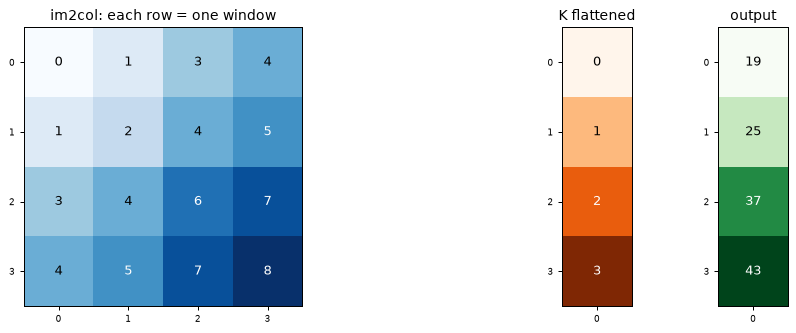

In [34]:
windows = sliding_window_view(X, K.shape)            # all 2x2 windows of the 3x3 X: shape (2, 2, 2, 2)
cols = windows.reshape(-1, K.size)                   # each window -> one row: shape (4, 4)
y_vec = cols @ K.ravel()                             # ONE matrix-vector product
print("rows = windows:\n", cols)
print("cols @ K =", y_vec, "-> reshaped:\n", y_vec.reshape(2, 2), "\n(same as corr2d: [[19, 25], [37, 43]])")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"width_ratios": [4, 1, 1]})
show_matrix(axes[0], cols, "im2col: each row = one window", cmap="Blues")
show_matrix(axes[1], K.reshape(-1, 1), "K flattened", cmap="Oranges")
show_matrix(axes[2], y_vec.reshape(-1, 1), "output", cmap="Greens")
plt.tight_layout(); plt.show()

### The convolutional layer
* **forward:** im2col + matrix multiplication + bias (multi-channel, multi-output, like §7.4).
* **backward:** $\partial L/\partial W$ = (windows)ᵀ × $\partial L/\partial Y$ — the same idea as A.6; $\partial L/\partial b$ = sum of $\partial L/\partial Y$;
  and $\partial L/\partial X$ = each window's gradient added back to where that window came from.

In [35]:
rng_init = np.random.default_rng(0)

def xavier(shape, fan_in, fan_out):
    '''Xavier (Glorot) uniform initialization, as used in the book for LeNet.'''
    limit = np.sqrt(6.0 / (fan_in + fan_out))
    return rng_init.uniform(-limit, limit, size=shape).astype(np.float32)

class Conv2D:
    '''Convolutional layer: input (N, C_in, H, W) -> output (N, C_out, H', W').'''
    def __init__(self, c_in, c_out, k, padding=0, first_layer=False):
        self.k, self.p, self.first = k, padding, first_layer
        self.W = xavier((c_out, c_in, k, k), c_in * k * k, c_out * k * k)   # c_o x c_i x k_h x k_w (§7.4.2)
        self.b = np.zeros(c_out, dtype=np.float32)
        self.params = [self.W, self.b]

    def forward(self, X):
        p, k = self.p, self.k
        Xp = np.pad(X, ((0, 0), (0, 0), (p, p), (p, p))) if p else X                  # padding (§7.3)
        N, C, Hp, Wp = Xp.shape
        Ho, Wo = Hp - k + 1, Wp - k + 1
        win = sliding_window_view(Xp, (k, k), axis=(2, 3))                            # (N, C, Ho, Wo, k, k)
        self.cols = win.transpose(0, 2, 3, 1, 4, 5).reshape(N * Ho * Wo, C * k * k)  # im2col
        self.shape = (N, C, Hp, Wp, Ho, Wo)
        out = self.cols @ self.W.reshape(len(self.W), -1).T + self.b                  # multiply & add, all at once
        return out.reshape(N, Ho, Wo, -1).transpose(0, 3, 1, 2)

    def backward(self, dY):
        N, C, Hp, Wp, Ho, Wo = self.shape
        k, p, O = self.k, self.p, len(self.W)
        dYm = dY.transpose(0, 2, 3, 1).reshape(-1, O)
        self.dW = (dYm.T @ self.cols).reshape(self.W.shape)       # gradient for the kernels
        self.db = dYm.sum(axis=0)                                 # gradient for the biases
        if self.first:                                            # first layer: nobody needs dX
            return None
        dcols = (dYm @ self.W.reshape(O, -1)).reshape(N, Ho, Wo, C, k, k)

        dXp = np.zeros((N, C, Hp, Wp), dtype=dY.dtype)

        for a in range(k):                                        # add each window's gradient back ("col2im")
            for b in range(k):
                dXp[:, :, a:a + Ho, b:b + Wo] += dcols[:, :, :, :, a, b].transpose(0, 3, 1, 2)
                
        return dXp[:, :, p:Hp - p, p:Wp - p] if p else dXp

    @property
    def grads(self): return [self.dW, self.db]

# quick check: our fast Conv2D layer gives the same answer as the slow corr2d loops
layer = Conv2D(1, 1, 3, padding=1)
fast = layer.forward(img[None, None].astype(np.float32))[0, 0]
slow = corr2d(img, layer.W[0, 0], padding=1) + layer.b[0]
print("Conv2D layer == corr2d loops:", np.allclose(fast, slow, atol=1e-2))

Conv2D layer == corr2d loops: True


### Activations, pooling, flatten, dense layer, and the loss
* **Sigmoid** $\sigma(x) = 1/(1+e^{-x})$, derivative $\sigma(1-\sigma)$. **ReLU** passes gradient only where $x>0$.
* **Average pooling** 2×2: each input cell gets ¼ of the output's gradient. **Max pooling** 2×2: only the max cell gets it.
* **Softmax + cross-entropy:** gradient w.r.t. the logits is simply $(\text{probabilities} - \text{one-hot label}) / N$.

In [36]:
class Sigmoid:
    params = grads = []
    def forward(self, X):
        self.Y = 1.0 / (1.0 + np.exp(-X)); return self.Y
    def backward(self, dY): return dY * self.Y * (1 - self.Y)

class ReLU:
    params = grads = []
    def forward(self, X):
        self.mask = X > 0; return X * self.mask
    def backward(self, dY): return dY * self.mask

class AvgPool2:
    '''2x2 average pooling, stride 2.'''
    params = grads = []
    def forward(self, X):
        N, C, H, W = X.shape
        return X.reshape(N, C, H // 2, 2, W // 2, 2).mean(axis=(3, 5))
    def backward(self, dY):
        return np.repeat(np.repeat(dY, 2, axis=2), 2, axis=3) / 4.0

class MaxPool2:
    '''2x2 max pooling, stride 2.'''
    params = grads = []
    def forward(self, X):
        N, C, H, W = X.shape
        Xr = X.reshape(N, C, H // 2, 2, W // 2, 2)
        Y = Xr.max(axis=(3, 5))
        mask = (Xr == Y[:, :, :, None, :, None])
        self.mask = mask / mask.sum(axis=(3, 5), keepdims=True)     # remember where the max was
        return Y
    def backward(self, dY):
        N, C, h, w = dY.shape
        return (self.mask * dY[:, :, :, None, :, None]).reshape(N, C, h * 2, w * 2)

class Flatten:
    params = grads = []
    def forward(self, X):
        self.shape = X.shape; return X.reshape(X.shape[0], -1)
    def backward(self, dY): return dY.reshape(self.shape)

class Linear:
    '''Fully-connected (dense) layer.'''
    def __init__(self, n_in, n_out):
        self.W = xavier((n_in, n_out), n_in, n_out)
        self.b = np.zeros(n_out, dtype=np.float32)
        self.params = [self.W, self.b]
    def forward(self, X):
        self.X = X; return X @ self.W + self.b
    def backward(self, dY):
        self.dW = self.X.T @ dY; self.db = dY.sum(axis=0)
        return dY @ self.W.T
    @property
    def grads(self): return [self.dW, self.db]

def softmax_cross_entropy(logits, y):
    z = logits - logits.max(axis=1, keepdims=True)            # for numerical stability
    P = np.exp(z); P /= P.sum(axis=1, keepdims=True)          # softmax probabilities
    N = len(y)
    loss = -np.log(P[np.arange(N), y] + 1e-12).mean()         # cross-entropy
    dlogits = P.copy(); dlogits[np.arange(N), y] -= 1; dlogits /= N
    return loss, dlogits, P

class Sequential:
    '''Chains layers: forward goes first -> last, backward goes last -> first.'''
    def __init__(self, *layers):
        self.layers = list(layers)
    def forward(self, X, keep=False):
        self.outputs = []
        for layer in self.layers:
            X = layer.forward(X)
            if keep: self.outputs.append(X)
        return X
    def backward(self, d):
        for layer in reversed(self.layers):
            d = layer.backward(d)
    def step(self, lr):                                        # minibatch SGD update
        for layer in self.layers:
            for P, G in zip(layer.params, layer.grads):
                P -= lr * G
    def predict(self, X, batch=1000):
        return np.concatenate([self.forward(X[k:k + batch]).argmax(1) for k in range(0, len(X), batch)])
    def num_params(self):
        return sum(P.size for layer in self.layers for P in layer.params)

### Is our backpropagation correct? A numerical gradient check
Nudge one weight by a tiny ε and see how the loss changes: $\frac{L(w+\epsilon) - L(w-\epsilon)}{2\epsilon}$.
It should match the gradient computed by `backward`.

In [37]:
rng_init = np.random.default_rng(1)
tiny = Sequential(Conv2D(1, 2, 3, padding=1), Sigmoid(), AvgPool2(), Flatten(), Linear(2 * 4 * 4, 3))
for layer in tiny.layers:                                  # use float64 for an exact check
    for name in ("W", "b"):
        if hasattr(layer, name): setattr(layer, name, getattr(layer, name).astype(np.float64))
    if hasattr(layer, "W"): layer.params = [layer.W, layer.b]
Xg = np.random.default_rng(2).normal(size=(4, 1, 8, 8)); yg = np.array([0, 1, 2, 1])

loss, d, _ = softmax_cross_entropy(tiny.forward(Xg), yg)
tiny.backward(d)
conv = tiny.layers[0]
for idx in [(0, 0, 0, 0), (1, 0, 2, 1)]:
    old = conv.W[idx]; eps = 1e-5
    conv.W[idx] = old + eps; lp = softmax_cross_entropy(tiny.forward(Xg), yg)[0]
    conv.W[idx] = old - eps; lm = softmax_cross_entropy(tiny.forward(Xg), yg)[0]
    conv.W[idx] = old
    print(f"kernel weight {idx}: numerical = {(lp - lm) / (2 * eps):+.8f} | backprop = {conv.dW[idx]:+.8f}")

kernel weight (0, 0, 0, 0): numerical = -0.02870988 | backprop = -0.02870988
kernel weight (1, 0, 2, 1): numerical = +0.00134125 | backprop = +0.00134125


## E.3 LeNet-5 (D2L §7.6.1)
LeNet (LeCun et al., 1998) was one of the first CNNs used in practice (reading digits on bank checks). Two parts:

* **Convolutional block:** 2 × (5×5 conv → **sigmoid** → 2×2 **average** pooling, stride 2); 6 then 16 output channels. The first conv uses padding 2.
* **Dense block:** 3 fully-connected layers with 120, 84 and 10 outputs.

Shapes: `1×28×28 → 6×28×28 → 6×14×14 → 16×10×10 → 16×5×5 → 400 → 120 → 84 → 10`


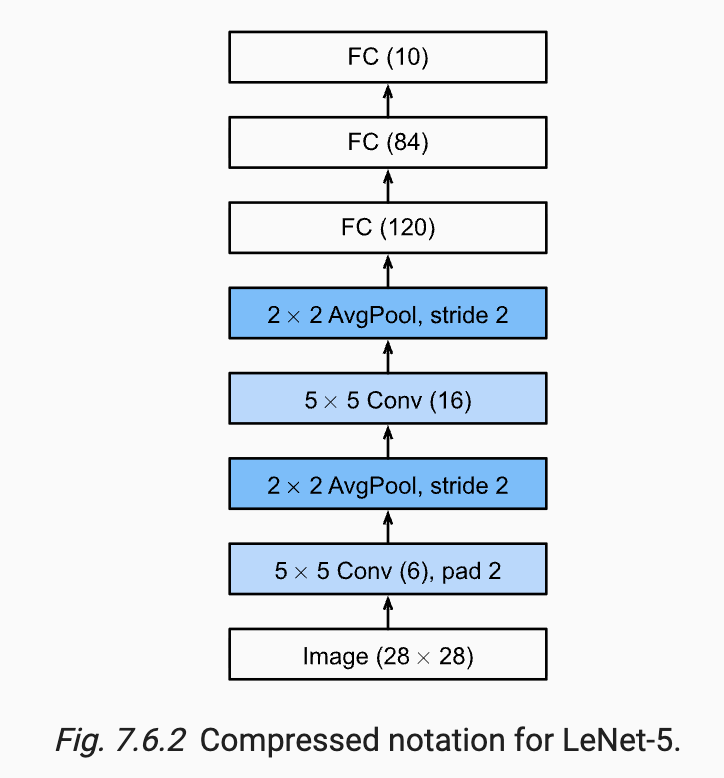

In [38]:
def make_lenet(modern=False, seed=0):
    global rng_init
    rng_init = np.random.default_rng(seed)                  # reproducible Xavier initialization
    Act = ReLU if modern else Sigmoid                       # D2L exercise 1: "modernize" LeNet
    Pool = MaxPool2 if modern else AvgPool2
    return Sequential(
        Conv2D(1, 6, 5, padding=2, first_layer=True), Act(), Pool(),
        Conv2D(6, 16, 5), Act(), Pool(),
        Flatten(),
        Linear(16 * 5 * 5, 120), Act(),
        Linear(120, 84), Act(),
        Linear(84, 10))

net = make_lenet()
Xs = np.random.default_rng(0).normal(size=(1, 1, 28, 28)).astype(np.float32)
for layer in net.layers:
    Xs = layer.forward(Xs)
    print(f"{layer.__class__.__name__:8s} output shape: {Xs.shape}")

print("\nLearnable parameters:")
for i, layer in enumerate(net.layers):
    for name, P in zip(["W", "b"], layer.params):
        print(f"  layer {i:2d} {layer.__class__.__name__:7s} {name}: {str(P.shape):16s} {P.size:6d}")
print("  TOTAL:", net.num_params())

Conv2D   output shape: (1, 6, 28, 28)
Sigmoid  output shape: (1, 6, 28, 28)
AvgPool2 output shape: (1, 6, 14, 14)
Conv2D   output shape: (1, 16, 10, 10)
Sigmoid  output shape: (1, 16, 10, 10)
AvgPool2 output shape: (1, 16, 5, 5)
Flatten  output shape: (1, 400)
Linear   output shape: (1, 120)
Sigmoid  output shape: (1, 120)
Linear   output shape: (1, 84)
Sigmoid  output shape: (1, 84)
Linear   output shape: (1, 10)

Learnable parameters:
  layer  0 Conv2D  W: (6, 1, 5, 5)        150
  layer  0 Conv2D  b: (6,)                  6
  layer  3 Conv2D  W: (16, 6, 5, 5)      2400
  layer  3 Conv2D  b: (16,)                16
  layer  7 Linear  W: (400, 120)        48000
  layer  7 Linear  b: (120,)              120
  layer  9 Linear  W: (120, 84)         10080
  layer  9 Linear  b: (84,)                84
  layer 11 Linear  W: (84, 10)            840
  layer 11 Linear  b: (10,)                10
  TOTAL: 61706


**✏️ Your turn:** verify two shapes with the formula from Part B:
1st conv: 28×28 input, 5×5 kernel, padding 2 on each side (total 4), stride 1 → ? 2nd conv: 14×14 input, 5×5 kernel, no padding → ?

<details><summary>Show answer</summary>

(28 − 5 + 4 + 1) = **28**; (14 − 5 + 0 + 1) = **10** ✔
</details>

## E.4 Data: Fashion-MNIST (as in the book)
70,000 grayscale 28×28 images of clothing in 10 classes. Downloaded once (~30 MB) and read with plain NumPy.
If you are offline, the notebook falls back to scikit-learn's built-in handwritten digits, enlarged to 28×28.

dataset: fashion | train: (60000, 1, 28, 28) | test: (10000, 1, 28, 28)


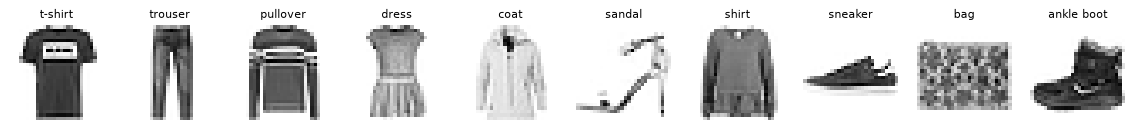

In [39]:
import gzip, os, urllib.request

def load_fashion_mnist(folder="data"):
    mirrors = ["https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
               "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/"]
    os.makedirs(folder, exist_ok=True)

    def read(name, offset):
        path = os.path.join(folder, name)
        if not os.path.exists(path):
            error = None
            for base in mirrors:
                try:
                    req = urllib.request.Request(base + name, headers={"User-Agent": "Mozilla/5.0"})
                    data_bytes = urllib.request.urlopen(req, timeout=60).read()
                    with open(path, "wb") as f:
                        f.write(data_bytes)
                    break
                except Exception as e:
                    error = e
            else:
                raise error
        with gzip.open(path) as f:
            return np.frombuffer(f.read(), np.uint8, offset=offset)   # skip the file header

    X_tr = read("train-images-idx3-ubyte.gz", 16).reshape(-1, 1, 28, 28).astype(np.float32) / 255
    y_tr = read("train-labels-idx1-ubyte.gz", 8).astype(np.int64)
    X_te = read("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 1, 28, 28).astype(np.float32) / 255
    y_te = read("t10k-labels-idx1-ubyte.gz", 8).astype(np.int64)
    return X_tr, y_tr, X_te, y_te

DATASET = "fashion"
try:
    X_train, y_train, X_test, y_test = load_fashion_mnist()
    class_names = ["t-shirt", "trouser", "pullover", "dress", "coat",
                   "sandal", "shirt", "sneaker", "bag", "ankle boot"]
except Exception as e:
    print("Fashion-MNIST not available (", type(e).__name__, ") -> using scikit-learn digits instead.")
    DATASET = "digits"
    Xd = np.repeat(np.repeat(digits.images, 3, axis=1), 3, axis=2)        # 8x8 -> 24x24 (each pixel -> 3x3 block)
    Xd = np.pad(Xd, ((0, 0), (2, 2), (2, 2)))[:, None].astype(np.float32) / 16.0   # -> (N, 1, 28, 28)
    perm = np.random.default_rng(0).permutation(len(Xd)); n_tr = int(0.75 * len(Xd))
    X_train, y_train = Xd[perm[:n_tr]], digits.target[perm[:n_tr]]
    X_test, y_test = Xd[perm[n_tr:]], digits.target[perm[n_tr:]]
    class_names = [str(d) for d in range(10)]

TRAIN_SIZE = None          # ⏱ on a slow computer, set e.g. 20000 to train on fewer images
if TRAIN_SIZE:
    X_train, y_train = X_train[:TRAIN_SIZE], y_train[:TRAIN_SIZE]

print("dataset:", DATASET, "| train:", X_train.shape, "| test:", X_test.shape)
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2))
for c in range(10):
    axes[c].imshow(X_train[y_train == c][0, 0], cmap="Greys"); axes[c].set_title(class_names[c], fontsize=9); axes[c].axis("off")
plt.show()

## E.5 Training (D2L §7.6.2)
Same settings as the book: **minibatch SGD, learning rate 0.1, batch size 128, 10 epochs, cross-entropy loss.**
Each step: forward → loss → **backward** (gradients for every kernel and weight) → **update**.

⏱ In pure NumPy this takes roughly **20–40 seconds per epoch** on a laptop (≈ 4–7 minutes in total).
Notice that the loss stays near **2.30** (= random guessing among 10 classes) for the first epochs before it starts dropping —
sigmoid networks start slowly. Part E.8 shows how a modern change fixes this.

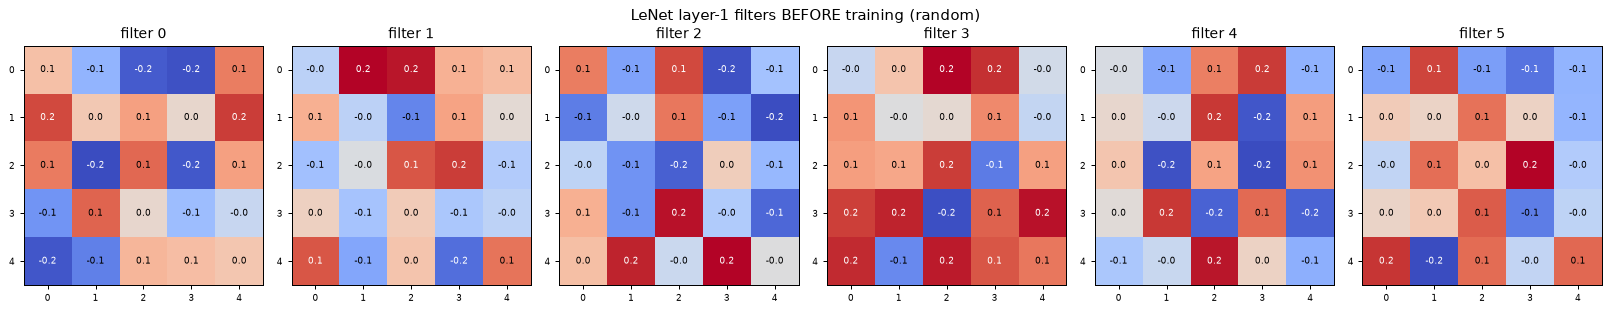

epoch   1 | loss 2.308 | train acc 0.099 | test acc 0.100 | 44s
epoch   2 | loss 2.306 | train acc 0.102 | test acc 0.100 | 43s
epoch   3 | loss 2.298 | train acc 0.118 | test acc 0.257 | 44s
epoch   4 | loss 1.905 | train acc 0.347 | test acc 0.504 | 42s
epoch   5 | loss 1.186 | train acc 0.564 | test acc 0.602 | 47s
epoch   6 | loss 0.993 | train acc 0.630 | test acc 0.642 | 56s
epoch   7 | loss 0.888 | train acc 0.672 | test acc 0.685 | 71s
epoch   8 | loss 0.830 | train acc 0.695 | test acc 0.706 | 55s
epoch   9 | loss 0.782 | train acc 0.713 | test acc 0.720 | 44s
epoch  10 | loss 0.735 | train acc 0.727 | test acc 0.705 | 42s
total training time: 489 s


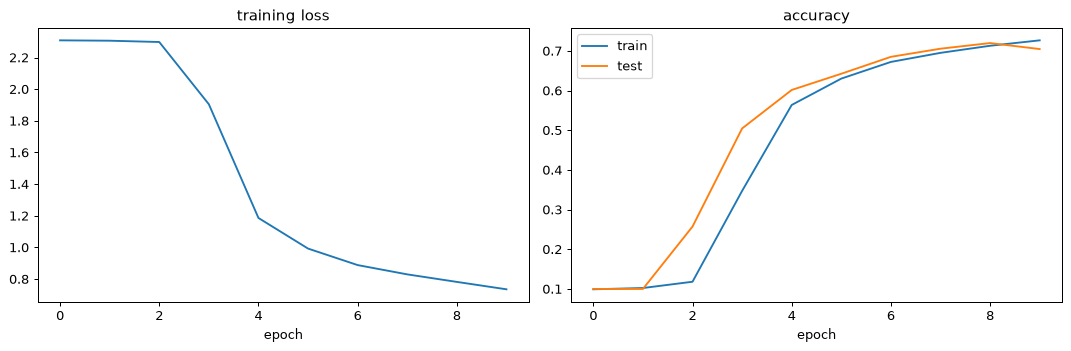

In [40]:
def train(net, epochs, lr=0.1, batch_size=128, seed=0):
    rng = np.random.default_rng(seed)
    hist = {"loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(epochs):
        t0 = time.time()
        perm = rng.permutation(len(X_train)); total_loss = 0.0; correct = 0
        for k in range(0, len(perm), batch_size):
            idx = perm[k:k + batch_size]
            logits = net.forward(X_train[idx])                               # 1. forward
            loss, dlogits, _ = softmax_cross_entropy(logits, y_train[idx])   # 2. how wrong?
            net.backward(dlogits)                                            # 3. backpropagation
            net.step(lr)                                                     # 4. update kernels & weights
            total_loss += loss * len(idx); correct += (logits.argmax(1) == y_train[idx]).sum()
        hist["loss"].append(total_loss / len(perm))
        hist["train_acc"].append(correct / len(perm))
        hist["test_acc"].append((net.predict(X_test) == y_test).mean())
        if epochs <= 20 or epoch % (epochs // 10) == 0 or epoch == epochs - 1:
            print(f"epoch {epoch+1:3d} | loss {hist['loss'][-1]:.3f} | train acc {hist['train_acc'][-1]:.3f} | "
                  f"test acc {hist['test_acc'][-1]:.3f} | {time.time() - t0:.0f}s")
    return hist

# The small digits fallback has far fewer images per epoch, so it needs more epochs.
EPOCHS = 10 if DATASET == "fashion" else 100

def plot_first_layer_filters(net, title): # function to plot filters

    w = net.layers[0].W[:, 0] # Access to Model where layers 0(layers[0])

    fig, axes = plt.subplots(1, 6, figsize=(18, 3.3))
    for k in range(6):
        m = np.abs(w[k]).max()
        show_matrix(axes[k], w[k], f"filter {k}", cmap="coolwarm", vmin=-m, vmax=m, fmt="{:.1f}", fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

#call funtion to plot filters
net = make_lenet()
plot_first_layer_filters(net, "LeNet layer-1 filters BEFORE training (random)")


t_start = time.time() # save time before train
hist = train(net, EPOCHS) # Train model  and save hist[loss, train_acc, and test_acc]
print(f"total training time: {time.time() - t_start:.0f} s") # print out the total train time for all epoches


# plot graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"]); axes[0].set_title("training loss"); axes[0].set_xlabel("epoch") # plot graph of training loss.
axes[1].plot(hist["train_acc"], label="train"); axes[1].plot(hist["test_acc"], label="test") # plot train and test acc
axes[1].set_title("accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend() # put title to graph
plt.tight_layout(); plt.show() # show graphs/print out graphs

### The filters AFTER training — the network learned its own kernels

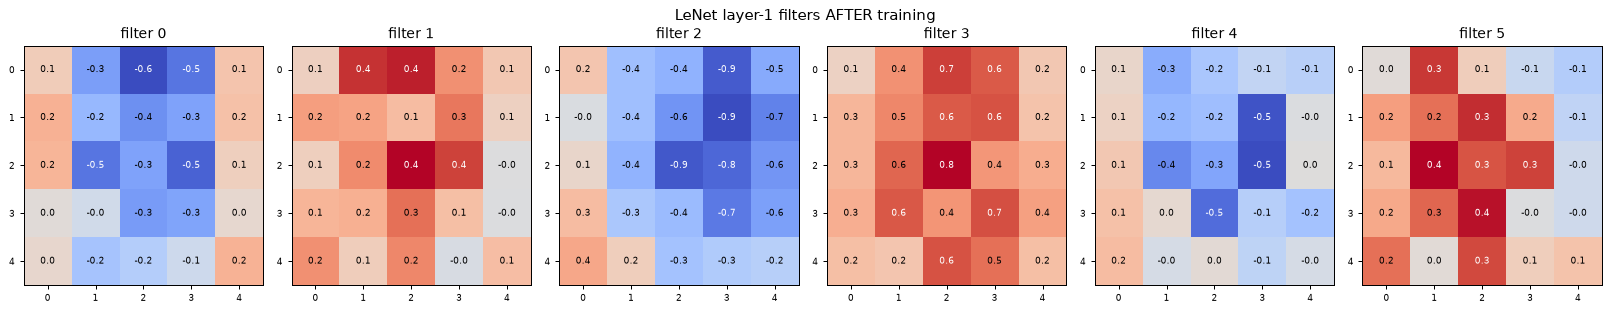

In [41]:
plot_first_layer_filters(net, "LeNet layer-1 filters AFTER training")

**✏️ Discuss:** do any learned filters look like the edge detectors from Part A (positive on one side, negative on the other)?

## E.6 What does LeNet "see"? Feature maps (D2L §7.6 exercise 4)
We pass two images from **similar** classes (for Fashion-MNIST: *pullover* vs *coat*) through the network and look at the
activations of the 1st conv layer (6 maps, 28×28) and the 2nd conv layer (16 maps, 10×10).

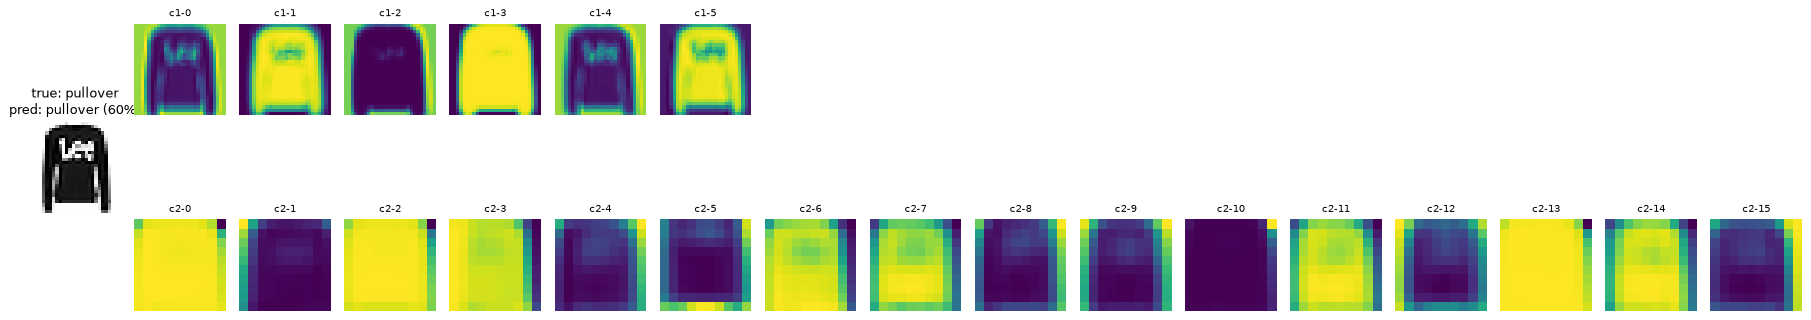

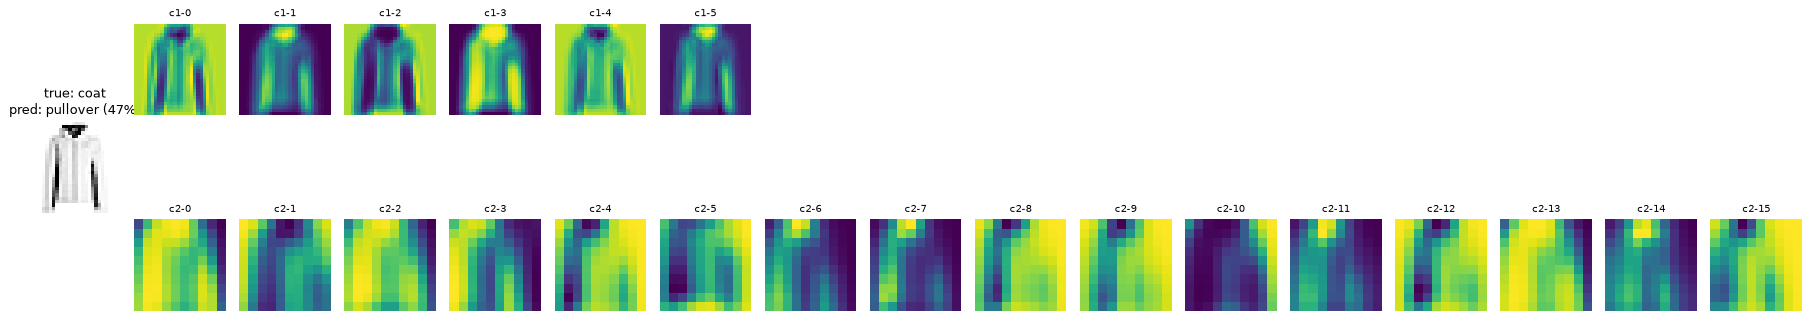

In [42]:
def get_activations(net, x):
    logits = net.forward(x, keep=True)
    probs = softmax_cross_entropy(logits, np.zeros(len(x), dtype=int))[2][0]
    return {"conv1": net.outputs[1][0], "conv2": net.outputs[4][0]}, probs   # after conv + activation

pair = (2, 4) if DATASET == "fashion" else (3, 8)

for c in pair:
    i = int(np.where(y_test == c)[0][0])
    acts, p = get_activations(net, X_test[i:i+1])
    fig = plt.figure(figsize=(20, 4.5))
    ax = fig.add_subplot(2, 17, (1, 18)); ax.imshow(X_test[i, 0], cmap="Greys"); ax.axis("off")
    ax.set_title(f"true: {class_names[c]}\npred: {class_names[p.argmax()]} ({p.max():.0%})", fontsize=10)
    for k in range(6):
        ax = fig.add_subplot(2, 17, k + 2); ax.imshow(acts["conv1"][k], cmap="viridis"); ax.axis("off")
        ax.set_title(f"c1-{k}", fontsize=8)
    for k in range(16):
        ax = fig.add_subplot(2, 17, k + 19); ax.imshow(acts["conv2"][k], cmap="viridis"); ax.axis("off")
        ax.set_title(f"c2-{k}", fontsize=8)
    plt.tight_layout(); plt.show()

* **Layer 1** maps still look like the image: edges and outlines — **low-level features**.
* **Layer 2** maps are smaller and more abstract — **combinations** of edges (parts, textures).
* The dense block reads these features and outputs the class probabilities.

## E.7 Evaluation: confusion matrix and mistakes

Test accuracy: 0.705


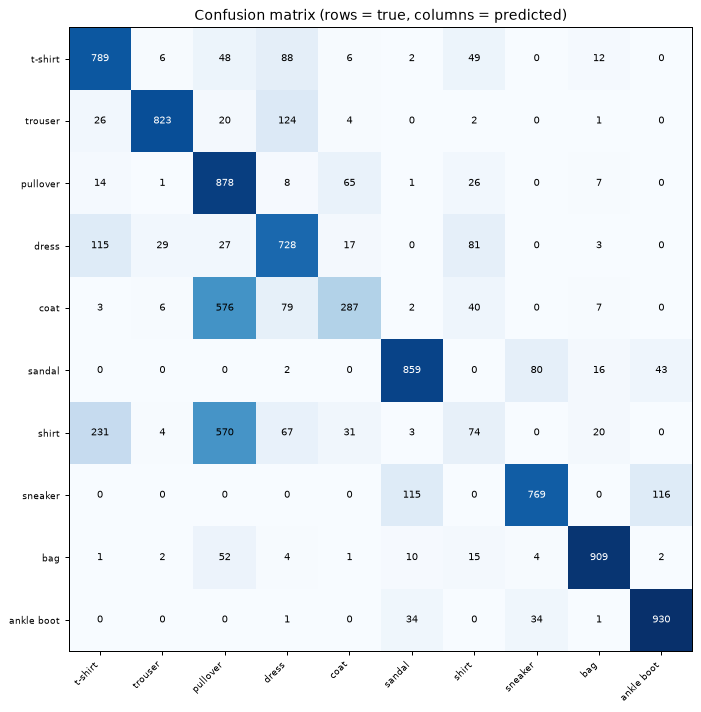

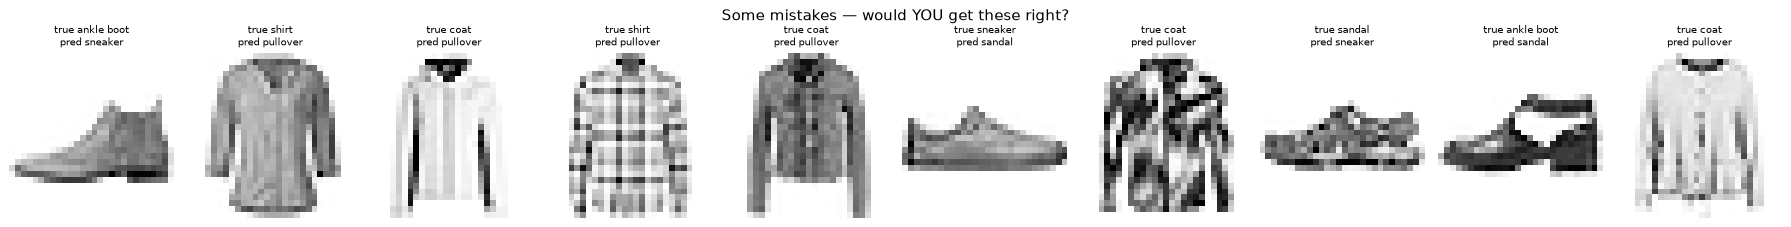

In [43]:
pred = net.predict(X_test)
print(f"Test accuracy: {(pred == y_test).mean():.3f}")

cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_test, pred), 1)                 # count (true, predicted) pairs
fig, ax = plt.subplots(figsize=(9, 9))
show_matrix(ax, cm, "Confusion matrix (rows = true, columns = predicted)", cmap="Blues", fontsize=8)
ax.set_xticklabels(class_names, rotation=45, ha="right"); ax.set_yticklabels(class_names)
plt.show()

wrong = np.where(pred != y_test)[0][:10]
fig, axes = plt.subplots(1, len(wrong), figsize=(2 * len(wrong), 2.6))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_test[i, 0], cmap="Greys"); ax.axis("off")
    ax.set_title(f"true {class_names[y_test[i]]}\npred {class_names[pred[i]]}", fontsize=8)
plt.suptitle("Some mistakes — would YOU get these right?"); plt.tight_layout(); plt.show()

## E.8 Modernize LeNet (D2L §7.6 exercise 1)
Replace **sigmoid → ReLU** and **average pooling → max pooling**. Same data, same training settings. Which learns faster?
(⏱ another few minutes of training)

epoch   1 | loss 0.805 | train acc 0.696 | test acc 0.806 | 58s
epoch   2 | loss 0.451 | train acc 0.831 | test acc 0.799 | 61s
epoch   3 | loss 0.382 | train acc 0.859 | test acc 0.857 | 118s
epoch   4 | loss 0.345 | train acc 0.872 | test acc 0.838 | 83s
epoch   5 | loss 0.320 | train acc 0.882 | test acc 0.866 | 60s
epoch   6 | loss 0.300 | train acc 0.889 | test acc 0.879 | 60s
epoch   7 | loss 0.286 | train acc 0.894 | test acc 0.872 | 60s
epoch   8 | loss 0.274 | train acc 0.898 | test acc 0.884 | 61s
epoch   9 | loss 0.265 | train acc 0.900 | test acc 0.886 | 60s
epoch  10 | loss 0.255 | train acc 0.904 | test acc 0.889 | 60s


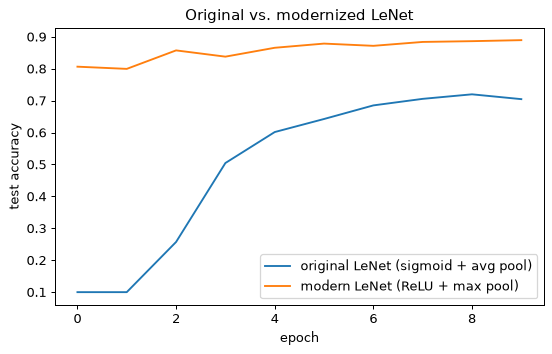

In [44]:
net_modern = make_lenet(modern=True)
hist_modern = train(net_modern, EPOCHS)

plt.figure(figsize=(7, 4))
plt.plot(hist["test_acc"], label="original LeNet (sigmoid + avg pool)")
plt.plot(hist_modern["test_acc"], label="modern LeNet (ReLU + max pool)")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend(); plt.title("Original vs. modernized LeNet"); plt.show()

## E.9 Why convolution instead of a plain dense network?

In [45]:
for H in [28, 224]:
    dense_params = (H * H) * 6 + 6           # dense layer: every pixel -> 6 neurons
    conv_params = 6 * (1 * 5 * 5) + 6        # LeNet's first conv layer: 6 filters of 5x5
    print(f"image {H:3d}x{H:<3d}: dense layer to 6 units = {dense_params:>9,} weights | conv layer with 6 filters = {conv_params} weights")

image  28x28 : dense layer to 6 units =     4,710 weights | conv layer with 6 filters = 156 weights
image 224x224: dense layer to 6 units =   301,062 weights | conv layer with 6 filters = 156 weights


* **Weight sharing:** the same small kernel is reused everywhere → few parameters, independent of image size.
* **Locality:** a 5×5 kernel looks at neighboring pixels, where edges and corners live.
* **Translation:** an edge detector finds an edge wherever it is (and pooling adds tolerance to small shifts).
* **Hierarchy:** stacking layers grows the receptive field: edges → parts → objects.

---
# Part F — Experiments, exercises & reflection

For each experiment, **write your prediction first**, then run and compare.

| # | Experiment | Section |
|---|---|---|
| 1 | Design a 3×3 kernel that detects **diagonal** lines (cell below). Then transpose both image and kernel — what happens? | §7.2 ex. 1 |
| 2 | Design a **blur** kernel and a **second-derivative** kernel. What is the smallest kernel that can compute a 2nd derivative? | §7.2 ex. 2 |
| 3 | Compute by hand the output shape for kernel (3, 5), padding (0, 1), stride (3, 4) on 8×8. Check with the cell in Part B. | §7.3 ex. 1 |
| 4 | Implement **mirror (reflect) padding** in `corr2d` with `np.pad(..., mode="reflect")`. How does the edge map of the photo change at the borders? | §7.3 ex. 3 |
| 5 | Are two stacked convolutions **without** an activation equivalent to one convolution? Test with `corr2d` twice vs. once with a bigger kernel. | §7.4 ex. 1 |
| 6 | Implement **average pooling as a convolution** with a 2×2 kernel of 0.25 and stride 2. Why can't max pooling be done this way? | §7.5 ex. 1–2 |
| 7 | Change LeNet: kernel sizes, number of channels, learning rate, epochs. Can you beat the modern LeNet? | §7.6 ex. 2 |
| 8 | Feed **random noise** into the trained LeNet and look at the activations and the prediction. | §7.6 ex. 5 |

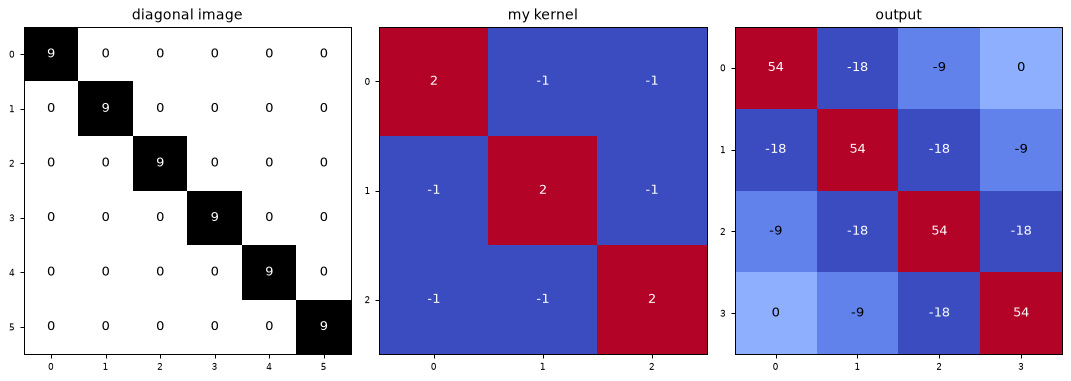

In [49]:
# ✏️ Experiment 1: your own diagonal detector
diag_img = np.eye(6) * 9
my_kernel = np.array([
    [2, -1, -1],     # TODO: change these numbers
    [-1, 2, -1],
    [-1, -1, 2],
], dtype=float)

show_side_by_side([diag_img, my_kernel, corr2d(diag_img, my_kernel)],
                  ["diagonal image", "my kernel", "output"], cmaps=["Greys", "coolwarm", "coolwarm"], figsize=(12, 4))

In [50]:
# ✏️ Experiment 6: average pooling as a convolution — fill in the kernel and compare
K_avg = np.full((2, 2), 0.25)          # TODO
print("pool2d avg   :\n", pool2d(F, (2, 2), "avg", stride=2))
print("corr2d stride 2:\n", corr2d(F, K_avg, stride=2))

pool2d avg   :
 [[1.   0.25]
 [0.   1.  ]]
corr2d stride 2:
 [[1.   0.25]
 [0.   1.  ]]


prediction for noise: pullover (49% confident)


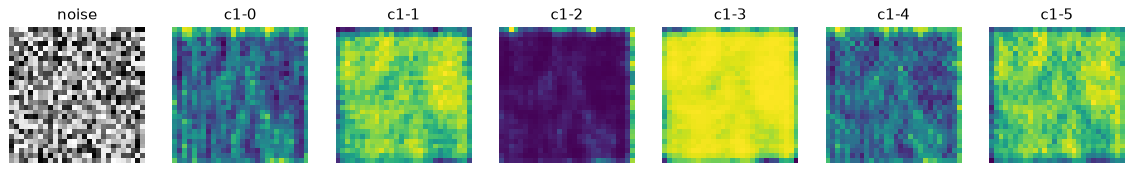

In [51]:
# ✏️ Experiment 8: random noise into the trained LeNet
noise = np.random.default_rng(0).random((1, 1, 28, 28)).astype(np.float32)
acts, p = get_activations(net, noise)
print("prediction for noise:", class_names[p.argmax()], f"({p.max():.0%} confident)")
fig, axes = plt.subplots(1, 7, figsize=(16, 2.6))
axes[0].imshow(noise[0, 0], cmap="Greys"); axes[0].set_title("noise"); axes[0].axis("off")
for k in range(6):
    axes[k + 1].imshow(acts["conv1"][k], cmap="viridis"); axes[k + 1].set_title(f"c1-{k}"); axes[k + 1].axis("off")
plt.show()

---


<details><summary>Show possible answers (1, 5, 6)</summary>

* **1.** `[[2, -1, -1], [-1, 2, -1], [-1, -1, 2]]` responds strongly along the main diagonal. Transposing a diagonal image gives the same image, so the output is unchanged.
* **5.** Yes: two 3×3 cross-correlations without an activation equal one 5×5 cross-correlation (the kernels combine). That's why we need **non-linear activations** between layers.
* **6.** `K_avg = np.full((2, 2), 0.25)`. Max is not a weighted sum (it's non-linear), so no fixed kernel can compute it.
</details>

### Student Tasks: Reflection questions
1. In your own words: what does **one** number in a feature map represent?
2. Why does the kernel `[[1, -1]]` give all zeros on the transposed image in A.5?
3. What does **padding** do? What does **stride** do? What does **pooling** do?
4. What is the difference between the kernels in A.5 and the kernels in E.5?
5. Why does a CNN need far fewer parameters than a dense network for images?
6. Looking at the confusion matrix, which classes are confused most? Why?
7. Why did the modern LeNet (ReLU + max pooling) train faster than the original?



## Answer Section:

1. One number in a feature map shows how strongly the kernel's pattern (for example an edge) matches the small patch of the image that the kernel is looking at, at that position. A big value means the pattern is there; a value near zero means it is not. The whole feature map shows where in the image that pattern appears.
2. The kernel [[1, -1]] compares each pixel with its right-hand neighbour (it computes left minus right), so it only responds where the pixel values change from left to right, which is a vertical edge. In the transposed image the edges are horizontal, so inside every row all pixels have the same value. The left and right neighbours are always equal, so each window gives 1·a + (−1)·a = 0, and the whole output is zeros. To detect horizontal edges we need the transposed kernel, [[1], [-1]].
3. Padding adds extra rows and columns of zeros around the border of the input. It keeps the output from shrinking (with a 3×3 kernel and padding 1 the output has the same size as the input) and lets the kernel look at the border pixels more fully. Stride is how many pixels the kernel jumps at each step. A stride of 1 moves it one pixel at a time, while a stride of 2 skips every other position, so the output becomes smaller (about half the size). Pooling (max or average) summarizes each small window (for example 2×2) by one number, its maximum or its average. It has no learnable parameters, makes the feature map smaller, reduces computation, and makes the result less sensitive to small shifts of the object.
4. In A.5 the kernel [[1, -1]] was designed by hand: I chose the numbers myself so that it detects vertical edges, and it does only that one job. In E.5 the kernels (the 6 filters of 5×5 in the first LeNet layer) start as random numbers and are learned by training: backpropagation and gradient descent adjust them to reduce the classification loss on the clothing images. The learned kernels are not designed for a human purpose; they are whatever patterns help to tell the classes apart, and some of them end up looking like edge detectors, while others look like blobs or textures. So hand-made kernels are fixed and have one purpose, while learned kernels are parameters that the network finds by itself from data.
5. A dense layer connects every pixel to every neuron, so its number of weights grows with the image size (for a 224×224 image, a dense layer to just 6 units already needs about 301,000 weights, and for 28×28 it needs 4,710). A convolutional layer uses weight sharing: the same small kernel (for example 5×5) is reused at every position of the image, so the number of parameters depends only on the kernel size and the number of filters (6 filters of 5×5 = 156 weights), not on the image size. It also uses locality: each output looks only at a small neighborhood of pixels, where edges and corners live, so it does not need a weight for every pair of distant pixels. Fewer parameters means less memory, faster training and less overfitting.
6. The most confused classes are upper-body clothes. Coats were predicted as pullovers 576 times (only 287 coats were correct) and shirts were predicted as pullovers 570 times and as t-shirts 231 times (only 74 of 1000 shirts were correct, the worst class). Other mistakes are sneaker vs. ankle boot (116) and sneaker vs. sandal (115), and trouser vs. dress (124). This happens because these classes look very similar in 28×28 grayscale images: coats, pullovers and shirts all have the same overall shape (a torso with two sleeves), and they differ only in small details such as buttons, collars or texture, which are hard to see in such a small image. A small network trained for a few epochs (test accuracy 0.705) learns mostly the overall shape, so it mixes them up. Classes with a very different shape, such as bag, ankle boot, trouser and sandal, are recognized much better.
7. In my run the modern LeNet (ReLU + max pooling) reached 0.806 test accuracy after the first epoch and 0.889 after 10 epochs, while the original LeNet (sigmoid + average pooling) stayed at about 0.10 (random guessing) for the first two epochs and only reached about 0.70 after 10 epochs. The main reason is the activation function. Sigmoid squashes every value into the range 0 to 1, and its gradient is at most 0.25 and becomes almost zero for large or small inputs (it saturates). During backpropagation these small gradients are multiplied layer after layer, so the early layers receive a very weak learning signal and learn slowly (the vanishing gradient problem). ReLU has a gradient of exactly 1 for positive inputs, so the gradient passes through without shrinking, and it is also cheaper to compute. Max pooling also helps because it passes the gradient to the strongest value in each window and keeps the strongest feature responses, while average pooling blurs them together.

---
### Summary
* **Cross-correlation / convolution** = slide a small kernel over the input; at each position multiply element-wise and sum → one number (§7.2).
* **Padding** and **stride** control the output size: $\lfloor (n - k + p + s)/s \rfloor$ (§7.3).
* Multiple **input channels** are summed; each **output channel** has its own kernel; 1×1 conv mixes channels (§7.4).
* **Pooling** (max/average) reduces resolution and adds shift tolerance, with no parameters (§7.5).
* **LeNet** stacks conv → activation → pool blocks, then dense layers to **classify**; training **learns** all kernels (§7.6).

*Reference:* Zhang, Lipton, Li & Smola, *Dive into Deep Learning*, Chapter 7 — https://d2l.ai/chapter_convolutional-neural-networks/